<a href="https://colab.research.google.com/github/tvml/ml2627/blob/master/codici/regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressione su housing price

Questo notebook applica la regressione lineare a un dataset reale, il classico *Boston Housing*, seguendo il percorso delle note sulla regressione lineare: dalla regressione su una sola feature, valutata in modo via via più corretto (training set, test set, cross validation), all'uso di funzioni base polinomiali, alla regolarizzazione (Lasso, Ridge, Elastic Net) e infine alla scelta degli iperparametri (*model selection*).

Il filo conduttore è una domanda che ritorna in tutti i passaggi: **quanto è affidabile la stima dell'errore che stiamo calcolando?** L'errore misurato sugli stessi dati usati per apprendere il modello è ottimista; quello su un singolo test set dipende dalla partizione scelta; la cross validation riduce questa dipendenza, ma solo se le partizioni sono costruite in modo corretto. Vedremo concretamente, su questo dataset, come ognuna di queste scelte cambia i risultati.

In [1]:
from IPython.display import Image
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import scipy.stats as st
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LassoCV, RidgeCV
import seaborn as sns
import copy

La cella seguente imposta l'aspetto dei grafici. Usiamo **seaborn**, che costruisce su matplotlib grafici statistici con uno stile più curato e lavora direttamente con i `DataFrame` di pandas; matplotlib resta disponibile per le parti che seaborn non copre, come le annotazioni di testo. Fissiamo anche un seme per il generatore di numeri casuali, in modo che partizioni e risultati siano riproducibili.

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

colors = ['xkcd:pale orange', 'xkcd:sea blue', 'xkcd:pale red', 'xkcd:sage green', 'xkcd:terra cotta', 'xkcd:dull purple', 'xkcd:teal', 'xkcd:goldenrod', 'xkcd:cadet blue', 
          'xkcd:scarlet']
# mappa di colori per le heatmap (cm.get_cmap non esiste più nelle versioni recenti di matplotlib)
cmap_big = mpl.colormaps['Spectral'].resampled(512)
cmap = mpl.colors.ListedColormap(cmap_big(np.linspace(0.7, 0.95, 256)))

bbox_props = dict(boxstyle="round,pad=0.3", fc=colors[0], alpha=.5)

SEED = 0
np.random.seed(SEED)

Per evitare di ripetere lo stesso codice in molte celle, definiamo due funzioni di supporto per i grafici più frequenti:

- `plot_fit` mostra i dati (eventualmente distinti in training e test set) e la curva di regressione appresa;
- `plot_residui` mostra i **residui** $y_i-t_i$ in funzione delle predizioni $y_i$, insieme alla loro distribuzione.

In [4]:
def plot_fit(model, X, y, feat, title, X_test=None, y_test=None, text=None, npoints=200):
    """Dati e curva di regressione di un modello con una sola feature."""
    fig, ax = plt.subplots(figsize=(16, 8))
    if X_test is None:
        sns.scatterplot(x=X.ravel(), y=y, color=colors[8], edgecolor='xkcd:light grey', s=50, ax=ax)
    else:
        sns.scatterplot(x=X.ravel(), y=y, color=colors[8], edgecolor='xkcd:light grey', s=50, label='Train', ax=ax)
        sns.scatterplot(x=X_test.ravel(), y=y_test, color=colors[0], edgecolor='black', s=50, label='Test', ax=ax)
    x = np.linspace(X.min(), X.max(), npoints).reshape(-1, 1)
    sns.lineplot(x=x.ravel(), y=model.predict(x), color=colors[2], linewidth=3, ax=ax)
    ax.set_xlabel(feat)
    ax.set_ylabel('MEDV (migliaia di $)')
    ax.set_title(title)
    if text is not None:
        ax.text(0.98, 0.95, text, fontsize=12, transform=ax.transAxes, bbox=bbox_props, ha='right', va='top')
    plt.show()

def plot_residui(y_pred, y, title='', text=None):
    """Residui in funzione delle predizioni, e istogramma dei residui."""
    res = y_pred - y
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [3, 1]}, sharey=True)
    sns.scatterplot(x=y_pred, y=res, color=colors[8], edgecolor='xkcd:light grey', s=50, ax=axes[0])
    axes[0].axhline(0, color=colors[2], lw=2)
    axes[0].set_xlabel(r'Valori predetti ($y_i$)')
    axes[0].set_ylabel(r'Residui ($y_i-t_i$)')
    axes[0].set_title(title)
    if text is not None:
        axes[0].text(0.98, 0.95, text, fontsize=12, transform=axes[0].transAxes, bbox=bbox_props, ha='right', va='top')
    sns.histplot(y=res, kde=True, color=colors[8], ax=axes[1])
    axes[1].axhline(0, color=colors[2], lw=2)
    axes[1].set_title('Distribuzione dei residui')
    plt.tight_layout()
    plt.show()

# Esame del dataset Housing

Il dataset raccoglie $506$ zone censuarie dell'area di Boston (anni '70). Per ciascuna sono riportate $13$ caratteristiche e il valore mediano delle abitazioni, `MEDV`, che è il target da predire:

<pre>
1. CRIM      per capita crime rate by town
2. ZN        proportion of residential land zoned for lots over 25,000 sq.ft.
3. INDUS     proportion of non-retail business acres per town
4. CHAS      Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
5. NOX       nitric oxides concentration (parts per 10 million)
6. RM        average number of rooms per dwelling
7. AGE       proportion of owner-occupied units built prior to 1940
8. DIS       weighted distances to five Boston employment centres
9. RAD       index of accessibility to radial highways
10. TAX      full-value property-tax rate per $10,000
11. PTRATIO  pupil-teacher ratio by town
12. B        1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town
13. LSTAT    % lower status of the population
14. MEDV     Median value of owner-occupied homes in $1000s
</pre>

Due osservazioni prima di iniziare. La feature `B` è costruita a partire dalla composizione etnica della popolazione, sulla base di ipotesi oggi considerate problematiche; per questo motivo il dataset è stato rimosso da scikit-learn, ed è un buon esempio di come le feature di un dataset incorporino scelte, e talvolta pregiudizi, di chi lo ha costruito. Inoltre il target è **troncato**: i valori di `MEDV` superiori a $50$ sono stati registrati come $50$, e questo produrrà un effetto visibile nei grafici dei residui.

Lettura del dataset in un dataframe pandas. La funzione `get_file` restituisce il percorso locale del file oppure, se il notebook è eseguito su Colab o se `local=False`, lo scarica dal sito del corso.

In [ ]:
import urllib.request

filepath = "../dataset/"
url = "https://tvml.github.io/ml2627/dataset/"

def get_file(filename, local=True):
    IS_COLAB = ('google.colab' in str(get_ipython()))
    if IS_COLAB or not local:
        urllib.request.urlretrieve(url+filename, filename)
        return filename
    else:
        return filepath+filename

In [6]:
df = pd.read_csv(get_file('housing.data.txt', local=False), header=None, sep=r'\s+')
df.columns = ['CRIM','ZN','INDUS','CHAS','NOX','RM','AGE','DIS','RAD','TAX','PTRATIO','B','LSTAT','MEDV']
df.shape

(506, 14)

Le statistiche descrittive mostrano scale molto diverse tra le feature (`NOX` è dell'ordine di $0.5$, `TAX` dell'ordine di qualche centinaio): questo sarà rilevante quando introdurremo la regolarizzazione.

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.61,8.60,0.01,0.08,0.26,3.68,88.98
ZN,506.0,11.36,23.32,0.00,0.00,0.00,12.50,100.00
INDUS,506.0,11.14,6.86,0.46,5.19,9.69,18.10,27.74
CHAS,506.0,0.07,0.25,0.00,0.00,0.00,0.00,1.00
NOX,506.0,0.55,0.12,0.38,0.45,0.54,0.62,0.87
RM,506.0,6.28,0.70,3.56,5.89,6.21,6.62,8.78
AGE,506.0,68.57,28.15,2.90,45.02,77.50,94.07,100.00
DIS,506.0,3.80,2.11,1.13,2.10,3.21,5.19,12.13
RAD,506.0,9.55,8.71,1.00,4.00,5.00,24.00,24.00
TAX,506.0,408.24,168.54,187.00,279.00,330.00,666.00,711.00


In [8]:
print('Zone con MEDV = 50 (valore troncato): {0:d}'.format((df['MEDV'] == 50).sum()))

Zone con MEDV = 50 (valore troncato): 16


## Visualizzazione delle caratteristiche del dataset

Matrice delle distribuzioni congiunte di alcune feature e del target: fuori dalla diagonale, il diagramma di dispersione di ogni coppia; sulla diagonale, una stima della densità di ogni singola variabile.

Si notano subito alcuni aspetti utili per il seguito: la relazione tra `LSTAT` e `MEDV` è chiaramente **non lineare** (decrescente e convessa), quella tra `RM` e `MEDV` è approssimativamente lineare ma con molti punti anomali, e la distribuzione di `MEDV` ha un picco artificiale in corrispondenza del valore troncato $50$.

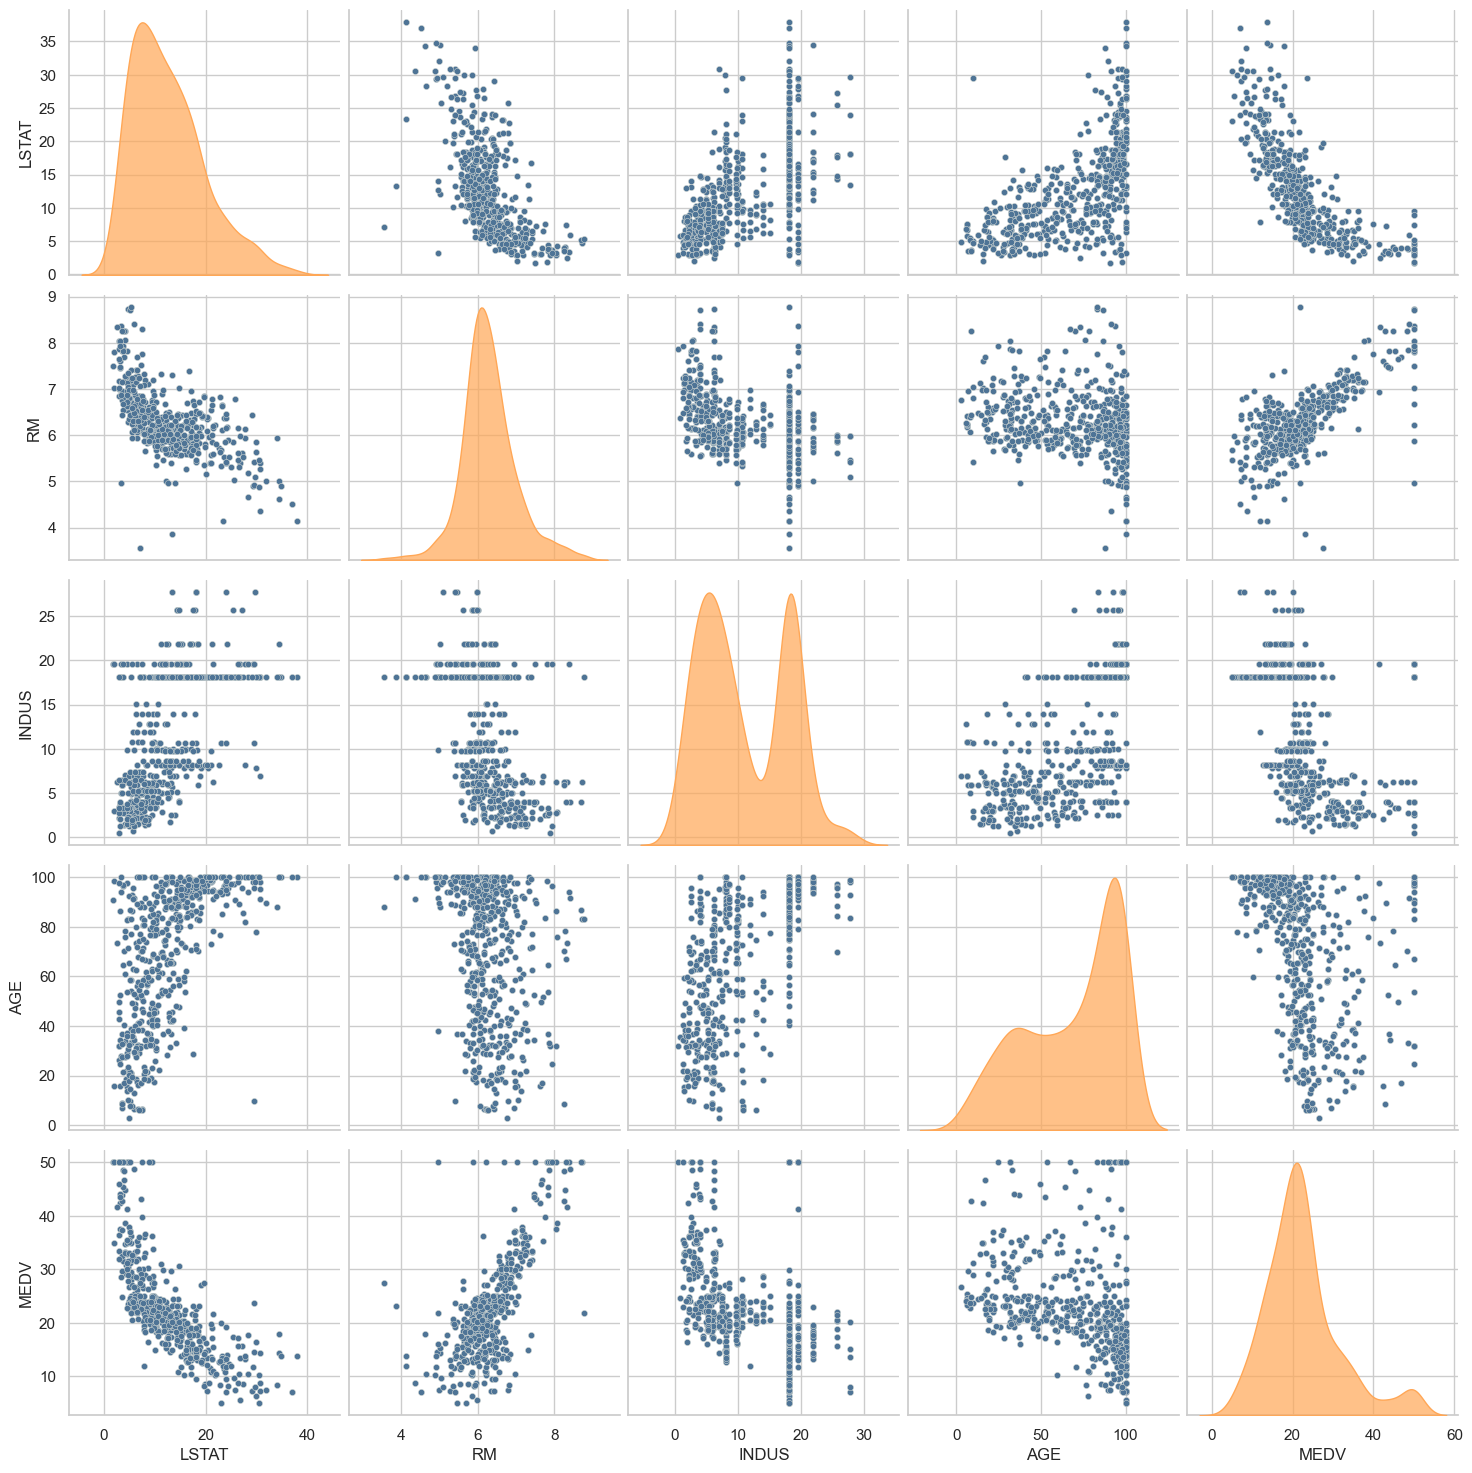

In [9]:
cols = ['LSTAT', 'RM', 'INDUS', 'AGE', 'MEDV']

sns.pairplot(df[cols], height=3, diag_kind='kde', 
             plot_kws=dict(color=colors[8], s=20, edgecolor='xkcd:light grey'), 
             diag_kws=dict(fill=True, alpha=.7, color=colors[0]))
plt.show()

Matrice di correlazione: alla posizione $(i,j)$ il coefficiente di correlazione di Pearson tra le feature $i$ e $j$,
$$\rho_{ij}=\frac{\mathrm{cov}(x_i,x_j)}{\sigma_i\sigma_j}\in[-1,1],$$
dove $1$ indica una correlazione lineare perfetta, $-1$ una correlazione inversa perfetta e $0$ l'assenza di correlazione **lineare** (non di dipendenza: due variabili possono essere fortemente dipendenti in modo non lineare e avere correlazione nulla).

Le feature più correlate con `MEDV` sono `LSTAT` (negativamente) e `RM` (positivamente). Si notano anche forti correlazioni tra feature, come tra `INDUS` e `AGE` o `LSTAT`: feature correlate portano informazione in parte ridondante e rendono instabili i coefficienti della regressione, un problema che la regolarizzazione aiuta a controllare.

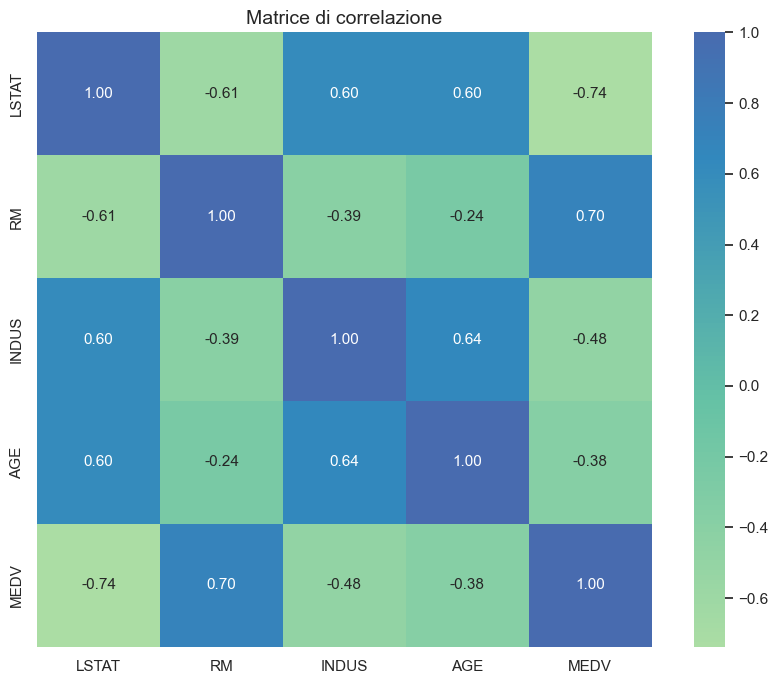

In [10]:
corr = df[cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cbar=True, annot=True, square=True, fmt='.2f', annot_kws={'size': 11}, cmap=cmap)
plt.title('Matrice di correlazione')
plt.tight_layout()
plt.show()

### Regressione di MEDV rispetto a una sola feature

Iniziamo dal caso più semplice: predire `MEDV` a partire da una sola feature. Per scegliere quale, misuriamo la **mutua informazione** tra ogni feature e il target,
$$I(X;T)=\int\!\!\int p(x,t)\log\frac{p(x,t)}{p(x)\,p(t)}\,dx\,dt,$$
che è nulla se e solo se $X$ e $T$ sono indipendenti, e, a differenza del coefficiente di correlazione, rileva qualunque tipo di dipendenza, anche non lineare. scikit-learn la stima a partire dai dati con un metodo basato sui vicini più prossimi.

In [11]:
print("Feature utilizzabili: {0}".format(', '.join(map(str, df.columns[:-1]))))

Feature utilizzabili: CRIM, ZN, INDUS, CHAS, NOX, RM, AGE, DIS, RAD, TAX, PTRATIO, B, LSTAT


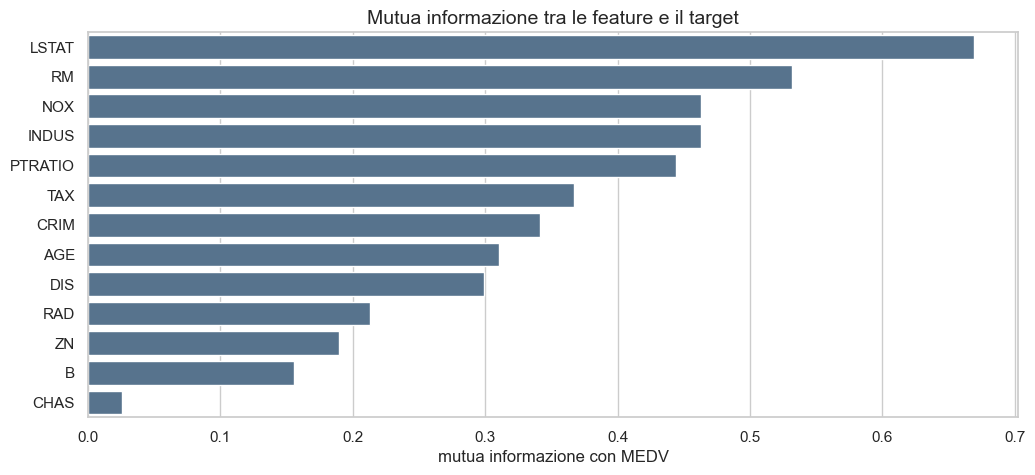

In [12]:
mi = mutual_info_regression(df[df.columns[:-1]], df[df.columns[-1]], random_state=SEED)
dmi = pd.DataFrame(mi, index=df.columns[:-1], columns=['mi']).sort_values(by='mi', ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(x=dmi['mi'], y=dmi.index, color=colors[8], orient='h')
plt.xlabel('mutua informazione con MEDV')
plt.ylabel('')
plt.title('Mutua informazione tra le feature e il target')
plt.show()

Utilizziamo la feature con mutua informazione massima, che risulta essere `LSTAT`, la percentuale di popolazione a basso reddito.

In [13]:
feat = dmi.index[0]
feat

'LSTAT'

In [14]:
X = df[[feat]].values
y = df['MEDV'].values

In `results` raccogliamo, per ogni modello, l'errore sul training set e la stima dell'errore di generalizzazione: alla fine del notebook li confronteremo in una tabella.

In [15]:
results = []

Regressione lineare standard: i coefficienti minimizzano la somma dei quadrati dei residui
$$E(\mathbf{w})=\frac{1}{2}\sum_{i=1}^n \bigl(y(\mathbf{x}_i;\mathbf{w}) - t_i\bigr)^2,$$
che, come visto nelle note, corrisponde alla stima di massima verosimiglianza sotto l'ipotesi di rumore gaussiano, e ha soluzione in forma chiusa data dalle equazioni normali.

In [16]:
# crea modello di regressione lineare
r = LinearRegression()
# ne apprende i coefficienti sui dati disponibili
r = r.fit(X, y)

Misura di qualità utilizzata: l'**errore quadratico medio** (MSE)
$$\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^n \bigl(y(\mathbf{x}_i;\mathbf{w}) - t_i\bigr)^2,$$
che si misura nel quadrato dell'unità del target (qui, migliaia di dollari al quadrato). La sua radice, la RMSE, è sulla stessa scala del target ed è più facile da interpretare.

In [17]:
p = r.predict(X)
# valuta MSE su dati e previsioni
mse = mean_squared_error(y, p)
print('w0: {0:.3f}, w1: {1:.3f}, MSE: {2:.3f}, RMSE: {3:.3f}'.format(r.intercept_, r.coef_[0], mse, np.sqrt(mse)))

w0: 34.554, w1: -0.950, MSE: 38.483, RMSE: 6.203


La retta cattura l'andamento decrescente, ma i dati mostrano una chiara curvatura: per valori bassi e alti di `LSTAT` la retta sottostima il prezzo, per valori intermedi lo sovrastima. Un modello lineare nella feature è qui troppo rigido (*underfitting*): ci torneremo con le funzioni base polinomiali.

Attenzione anche al significato dell'errore calcolato: è misurato **sugli stessi dati usati per apprendere** i coefficienti, ed è quindi una stima ottimista dell'errore su dati nuovi.

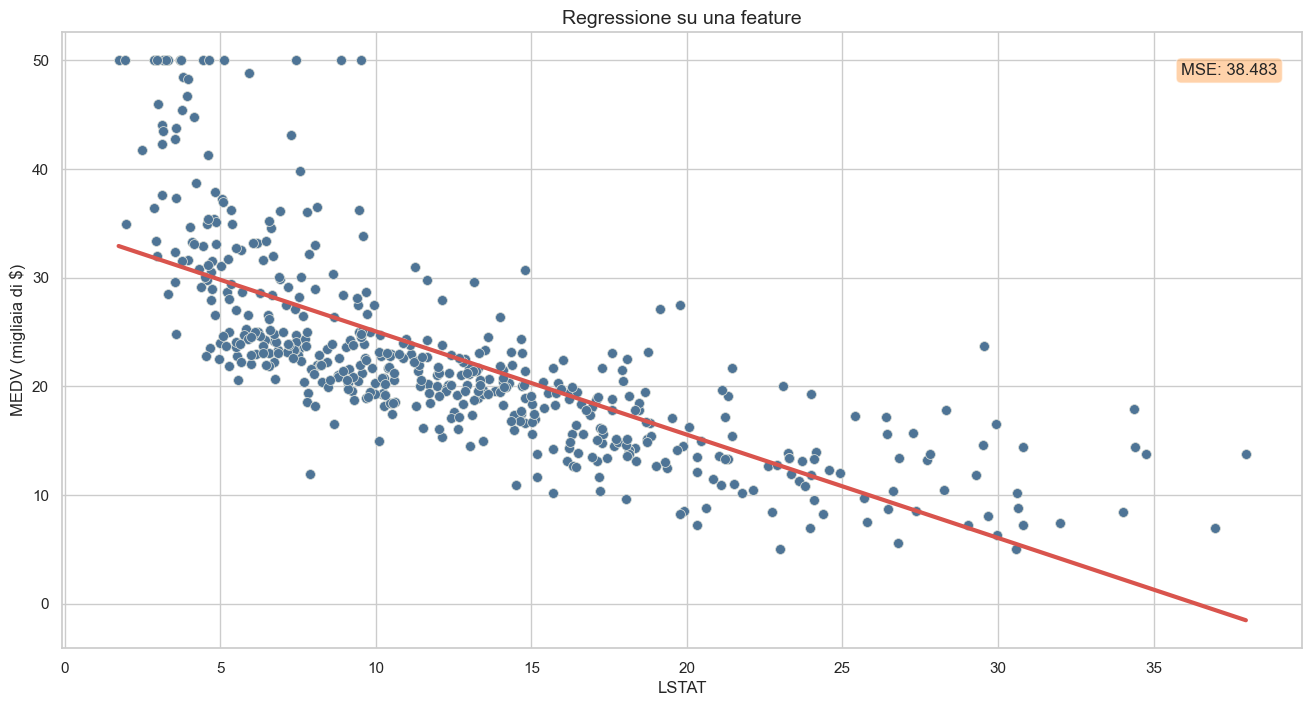

In [18]:
plot_fit(r, X, y, feat, 'Regressione su una feature', text='MSE: {0:.3f}'.format(mse))

Per stimare l'errore su dati nuovi, teniamo da parte una porzione del dataset, il **test set**, che non viene usata durante l'apprendimento. Fissiamo `random_state` per rendere la partizione riproducibile; la partizione è casuale, il che, come vedremo, è importante per questo dataset.

In [19]:
# partiziona dataset in training (80%) e test set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)

Creiamo una **pipeline** di scikit-learn con il solo modello di regressione: per ora è equivalente a usare direttamente il modello, ma permetterà di aggiungere passi di preprocessing senza modificare il resto del codice.

In [20]:
pipe = Pipeline([('regression', LinearRegression())])
pipe = pipe.fit(X_train, y_train)
p_train = pipe.predict(X_train)
p_test = pipe.predict(X_test)
mse_train = mean_squared_error(y_train, p_train)
mse_test = mean_squared_error(y_test, p_test)
r = pipe.named_steps['regression']
print('w0: {0:.3f}, w1: {1:.3f}, MSE-train: {2:.3f}, MSE-test: {3:.3f}'.format(r.intercept_, r.coef_[0], mse_train, mse_test))

w0: 34.765, w1: -0.956, MSE-train: 36.524, MSE-test: 46.336


In [21]:
results.append(['Regression, 1 feature', mse_train, mse_test])

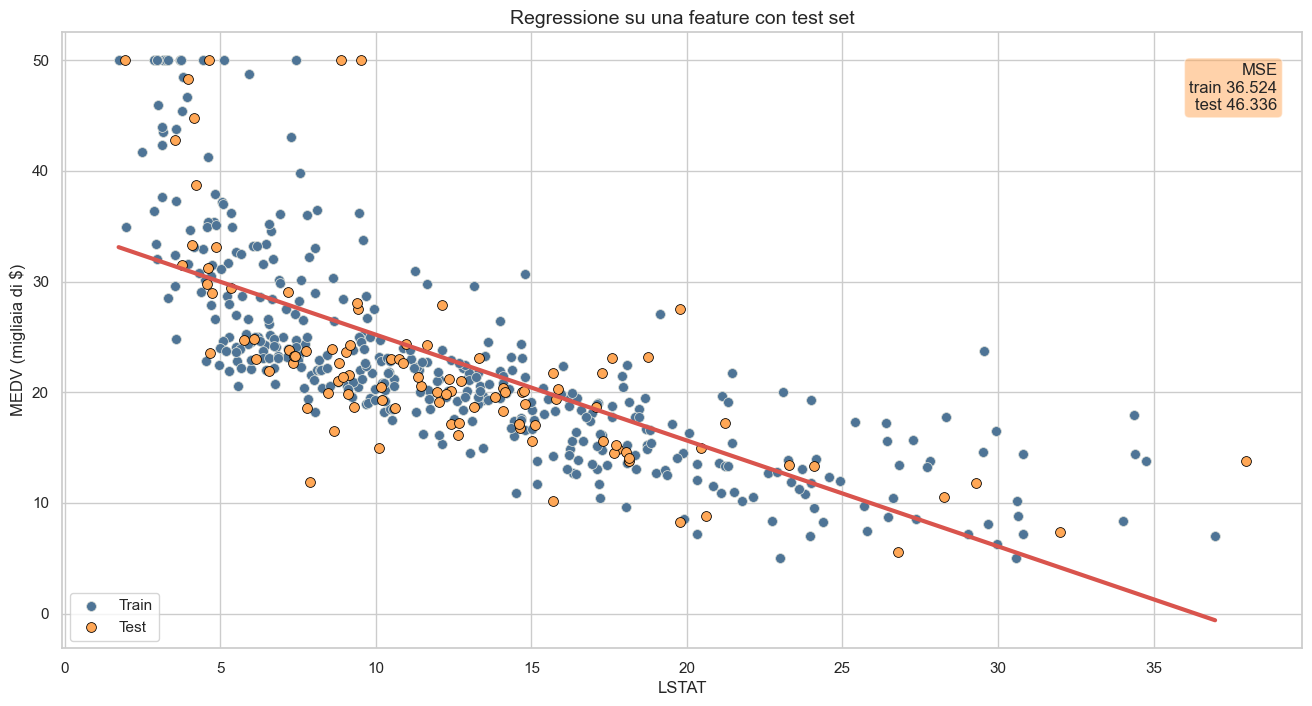

In [22]:
plot_fit(pipe, X_train, y_train, feat, 'Regressione su una feature con test set', X_test=X_test, y_test=y_test,
         text='MSE\ntrain {0:.3f}\ntest {1:.3f}'.format(mse_train, mse_test))

Aggiungiamo la **standardizzazione** della feature, che trasforma i valori in modo da ottenere media $0$ e varianza $1$:
$$x\mapsto\frac{x-\bar x}{s_x}.$$
La pipeline applica in sequenza lo `StandardScaler` e il modello di regressione. Un aspetto essenziale: media e deviazione standard sono calcolate **solo sul training set** (durante `fit`) e poi applicate anche al test set (durante `predict`). Calcolarle sull'intero dataset farebbe trapelare informazione dal test set nell'apprendimento (*data leakage*), e la pipeline evita questo errore per costruzione.

Per la regressione lineare senza regolarizzazione la standardizzazione **non cambia le predizioni**: cambiano i coefficienti, che compensano esattamente il cambio di scala, ma la retta è la stessa e gli errori sono identici a prima. Diventerà invece rilevante con la regolarizzazione, che penalizza i coefficienti e quindi dipende dalla scala delle feature, e con le funzioni base polinomiali, dove le potenze di valori grandi creano problemi numerici.

In [23]:
pipe = Pipeline([('scaler', StandardScaler()),('regression', LinearRegression())])
pipe = pipe.fit(X_train, y_train)

p_train = pipe.predict(X_train)
p_test = pipe.predict(X_test)
mse_train = mean_squared_error(y_train, p_train)
mse_test = mean_squared_error(y_test, p_test)
s = pipe.named_steps['scaler']
r = pipe.named_steps['regression']
print('Scaling: mean: {0:.3f}, var: {1:.3f}, scale: {2:.3f}'.format(s.mean_[0], s.var_[0], s.scale_[0]))
print('w0: {0:.3f}, w1: {1:.3f}, MSE-train: {2:.3f}, MSE-test: {3:.3f}'.format(r.intercept_, r.coef_[0], mse_train, mse_test))

Scaling: mean: 12.706, var: 53.144, scale: 7.290
w0: 22.612, w1: -6.973, MSE-train: 36.524, MSE-test: 46.336


Dopo la standardizzazione, l'intercetta $w_0$ coincide con la media di `MEDV` sul training set (la retta passa per il punto medio dei dati, che ora ha ascissa $0$), e $w_1$ indica la variazione del prezzo per un aumento di una deviazione standard di `LSTAT`.

In [24]:
results.append(['Regression, 1 feature, scaled', mse_train, mse_test])

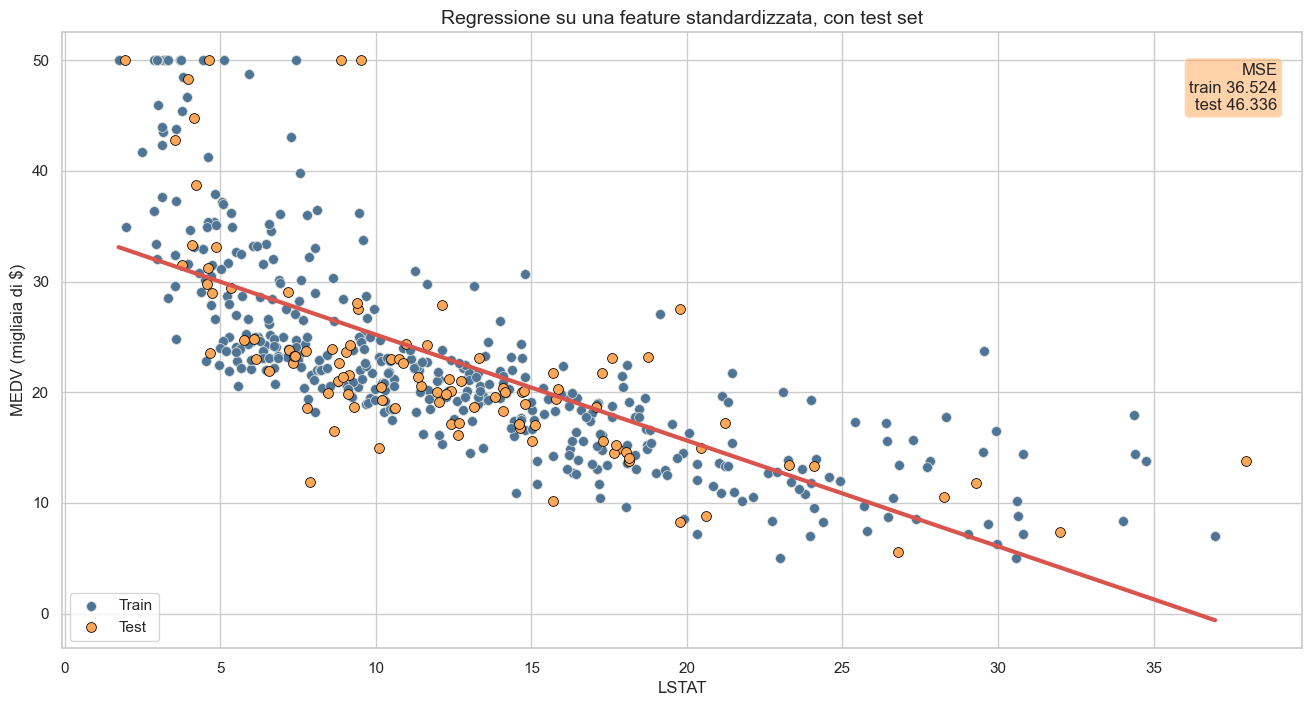

In [25]:
plot_fit(pipe, X_train, y_train, feat, 'Regressione su una feature standardizzata, con test set', X_test=X_test, y_test=y_test,
         text='MSE\ntrain {0:.3f}\ntest {1:.3f}'.format(mse_train, mse_test))

### Cross validation

La stima ottenuta con un singolo test set dipende dalla particolare partizione scelta: con un test set di circa $100$ elementi, la sua varianza non è trascurabile. La **cross validation** a $k$ fold suddivide il dataset in $k$ parti, usa a turno ciascuna come test set e le altre come training set, e media i $k$ errori ottenuti: ogni elemento è usato una volta per la valutazione, e la media riduce la dipendenza dalla partizione.

Sul dataset Housing c'è un dettaglio importante. Le righe **non sono in ordine casuale**: zone vicine, con caratteristiche simili, compaiono in posizioni consecutive. `KFold` per default costruisce i fold come blocchi consecutivi di righe, per cui ogni fold contiene zone sistematicamente diverse dalle altre, e la cross validation stima l'errore su una "popolazione" diversa da quella di training. Il confronto seguente mostra l'effetto: senza mescolamento gli errori sui singoli fold sono molto diversi tra loro e la media è più alta.

In [26]:
pipe = Pipeline([('scaler', StandardScaler()),('regression', LinearRegression())])
for shuffle in (False, True):
    kf = KFold(n_splits=5, shuffle=shuffle, random_state=SEED if shuffle else None)
    sc = -cross_val_score(pipe, X, y, cv=kf, scoring='neg_mean_squared_error')
    print('shuffle={0!s:5}: MSE per fold {1}, media {2:.2f}, dev. standard {3:.2f}'.format(shuffle, np.round(sc, 1), sc.mean(), sc.std()))

shuffle=False: MSE per fold [23.6 41.8 74.  50.5 23.2], media 42.62, dev. standard 18.90
shuffle=True : MSE per fold [46.3 33.1 31.  40.4 42.7], media 38.71, dev. standard 5.79


D'ora in poi usiamo quindi sempre fold costruiti dopo un mescolamento casuale delle righe, definendo una volta per tutte gli oggetti `KFold` da passare alle funzioni di scikit-learn (passando invece un intero, come `cv=5`, scikit-learn userebbe fold consecutivi).

Implementiamo prima la cross validation "a mano", iterando sulle coppie (training set, test set) prodotte da `KFold`: questo permette di esaminare i modelli appresi sui diversi fold.

In [27]:
kf5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
kf10 = KFold(n_splits=10, shuffle=True, random_state=SEED)

In [29]:
pipe = Pipeline([('scaler', StandardScaler()),('regression', LinearRegression())])
k_fold = KFold(n_splits=3, shuffle=True, random_state=SEED)
mse = []
preds = []
# itera su tutte le coppie (training set - test set)
for train, test in k_fold.split(X):
    # effettua l'apprendimento dei coefficienti sul training set
    r = pipe.fit(X[train], y[train])
    # appende in una lista una copia del modello appreso (pipe viene riutilizzato al passo successivo)
    preds.append(copy.deepcopy(r))
    mse.append(mean_squared_error(y[test], r.predict(X[test])))
for i, r in enumerate(preds):
    c = [r.named_steps['scaler'].mean_[0], r.named_steps['scaler'].scale_[0], r.named_steps['regression'].intercept_, 
         r.named_steps['regression'].coef_[0]]
    print('Fold: {0:2d}, mean: {1:.3f}, scale: {2:.3f}, w0: {3:.3f}, w1: {4:.3f}, MSE test set: {5:.3f}'.format(i, c[0], c[1], c[2], c[3], mse[i]))
# restituisce la media e la deviazione standard del MSE su tutti i fold
print('\nMSE - media: {0:.3f}, dev.standard: {1:.3f}'.format(np.mean(mse), np.std(mse)))

Fold:  0, mean: 12.401, scale: 7.009, w0: 22.811, w1: -6.930, MSE test set: 38.665
Fold:  1, mean: 12.820, scale: 7.308, w0: 22.608, w1: -6.979, MSE test set: 35.247
Fold:  2, mean: 12.738, scale: 7.074, w0: 22.180, w1: -6.417, MSE test set: 43.067

MSE - media: 38.993, dev.standard: 3.201


Le rette apprese sui diversi fold sono molto simili: con un solo parametro di pendenza e centinaia di punti, il modello ha **bassa varianza**. Il suo errore è dominato dal **bias**, cioè dall'incapacità di una retta di seguire la curvatura dei dati.

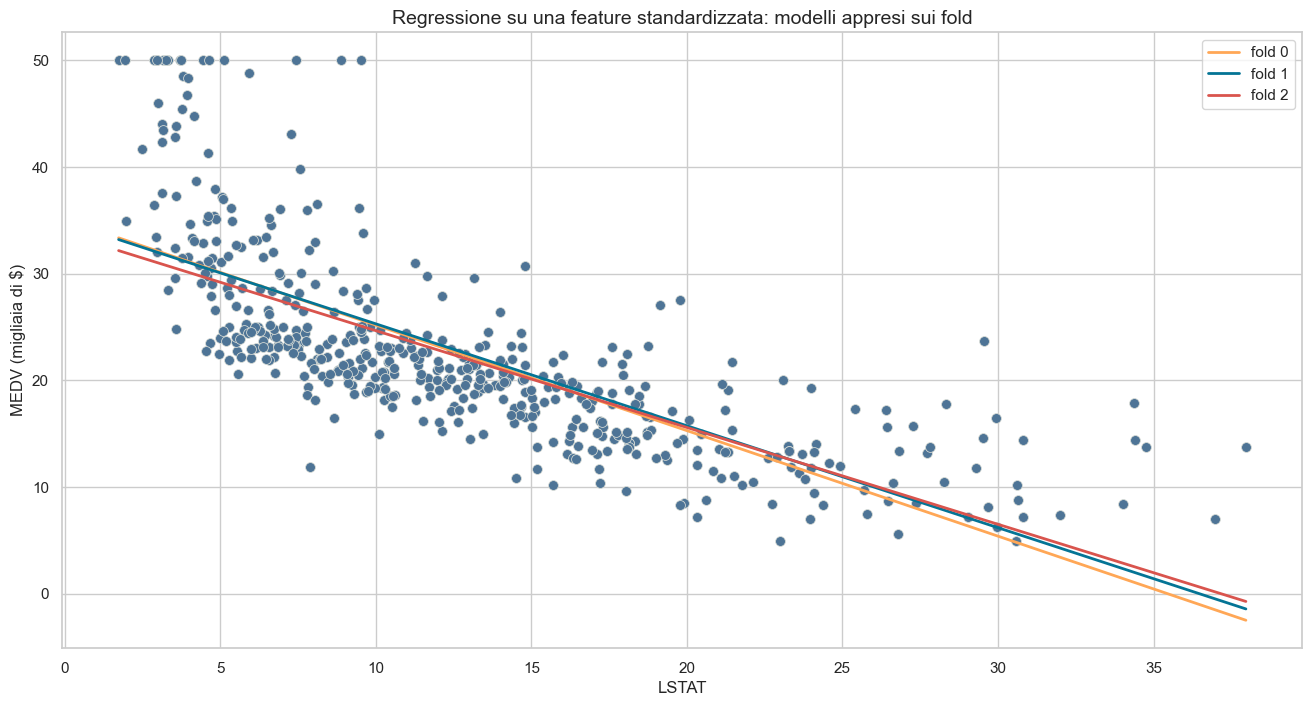

In [30]:
fig, ax = plt.subplots(figsize=(16, 8))
sns.scatterplot(x=X.ravel(), y=y, color=colors[8], edgecolor='xkcd:light grey', s=50, ax=ax)
x = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
for i, r in enumerate(preds):
    sns.lineplot(x=x.ravel(), y=r.predict(x), color=colors[i % 7], linewidth=2, label='fold {0:d}'.format(i), ax=ax)
ax.set_xlabel(feat)
ax.set_ylabel('MEDV (migliaia di $)')
ax.set_title('Regressione su una feature standardizzata: modelli appresi sui fold')
plt.show()

La funzione `cross_val_score` di scikit-learn effettua la stessa procedura in una sola chiamata. Per convenzione scikit-learn massimizza sempre uno *score*, per cui l'errore quadratico è restituito con segno negativo (`neg_mean_squared_error`) e va cambiato di segno.

Confrontiamo l'errore sul dataset completo (training) con la stima di cross validation: la differenza misura l'ottimismo dell'errore di training, qui piccolo perché il modello è molto semplice.

In [31]:
p = Pipeline([('scaler', StandardScaler()),('regression', LinearRegression())])
# apprende il modello su tutto il dataset
r = p.fit(X, y)
# errore sul dataset usato per l'apprendimento: stima ottimista
mse = mean_squared_error(y, r.predict(X))
# effettua la cross validation, derivando il costo sul test set per tutti i fold
scores = cross_val_score(estimator=p, X=X, y=y, cv=kf5, scoring='neg_mean_squared_error')
# calcola costo medio su tutti i fold
mse_cv = -scores.mean()
results.append(['Regression, 1 feature, scaled, CV', mse, mse_cv])

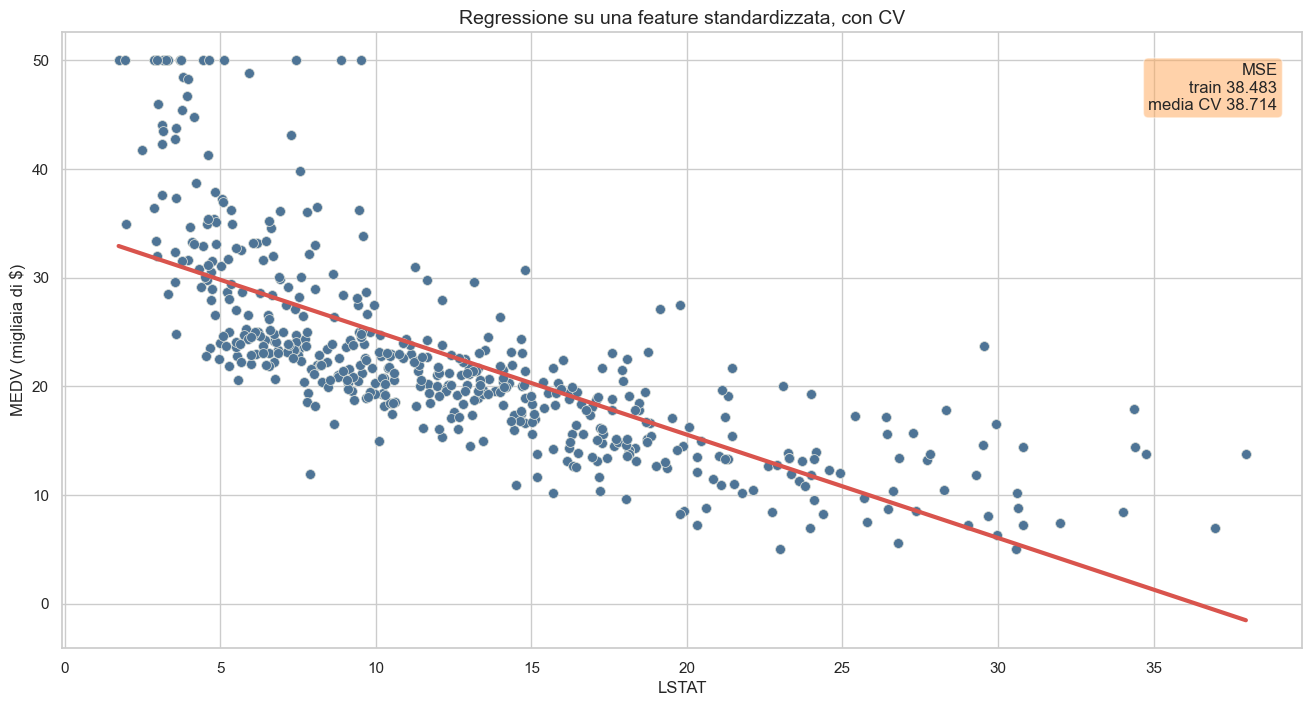

In [32]:
plot_fit(r, X, y, feat, 'Regressione su una feature standardizzata, con CV',
         text='MSE\ntrain {0:.3f}\nmedia CV {1:.3f}'.format(mse, mse_cv))

### Regressione con regolarizzazione

Come visto nelle note, la regolarizzazione aggiunge alla funzione di costo un termine che penalizza i coefficienti grandi. Attenzione alla parametrizzazione di scikit-learn, che differisce da classe a classe e dalle note (dove il coefficiente di regolarizzazione è indicato con $\lambda$; scikit-learn lo chiama `alpha`, da non confondere con la precisione del prior della regressione bayesiana).

Il **Lasso** (regolarizzazione L1) minimizza
$$E(\mathbf{w})=\frac{1}{2n}\sum_{i=1}^n \bigl(y(\mathbf{x}_i;\mathbf{w}) - t_i\bigr)^2+\alpha\sum_{j\ge1} |w_j|,$$
dove il termine d'errore è diviso per $n$ e l'intercetta $w_0$ non è penalizzata. La penalità L1 tende a produrre soluzioni **sparse**, con alcuni coefficienti esattamente nulli.

Con una sola feature la regolarizzazione può solo ridurre la pendenza della retta, e non può migliorare un modello che soffre di bias: ci aspettiamo che l'errore, sia di training sia di cross validation, aumenti leggermente.

In [33]:
#fissa un valore per l'iperparametro
alpha = 0.5
p = Pipeline([('scaler', StandardScaler()),('regression', Lasso(alpha=alpha))])
r = p.fit(X, y)
mse = mean_squared_error(y, r.predict(X))
scores = cross_val_score(estimator=p, X=X, y=y, cv=kf10, scoring='neg_mean_squared_error')
mse_cv = -scores.mean()
results.append(['Regression L1, 1 feature, scaled, CV, alpha=0.5', mse, mse_cv])
print('w1: {0:.3f}, MSE train: {1:.3f}, MSE CV: {2:.3f}'.format(r.named_steps['regression'].coef_[0], mse, mse_cv))

w1: -6.278, MSE train: 38.733, MSE CV: 39.261


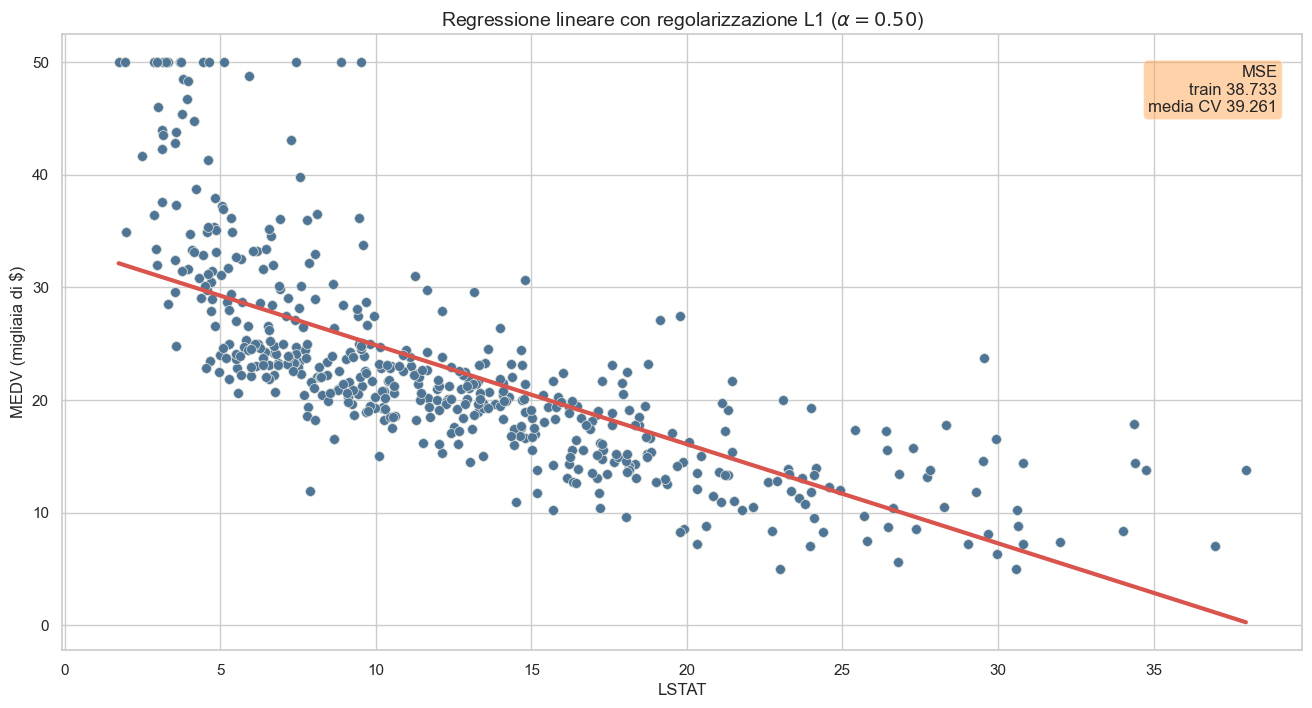

In [34]:
plot_fit(r, X, y, feat, r'Regressione lineare con regolarizzazione L1 ($\alpha={0:.2f}$)'.format(alpha),
         text='MSE\ntrain {0:.3f}\nmedia CV {1:.3f}'.format(mse, mse_cv))

La **Ridge regression** (regolarizzazione L2) di scikit-learn minimizza
$$E(\mathbf{w})=\sum_{i=1}^n \bigl(y(\mathbf{x}_i;\mathbf{w}) - t_i\bigr)^2+\alpha\sum_{j\ge1} w_j^2,$$
senza dividere il termine d'errore per $n$: a parità di effetto, i valori di $\alpha$ adatti alla Ridge sono quindi molto più grandi di quelli adatti al Lasso. La penalità L2 riduce tutti i coefficienti verso zero senza annullarli.

In [35]:
#fissa un valore per l'iperparametro
alpha = 0.5
p = Pipeline([('scaler', StandardScaler()),('regression', Ridge(alpha=alpha))])
r = p.fit(X, y)
scores = cross_val_score(estimator=p, X=X, y=y, cv=kf10, scoring='neg_mean_squared_error')
mse = mean_squared_error(y, r.predict(X))
mse_cv = -scores.mean()
results.append(['Regression L2, 1 feature, scaled, CV, alpha=0.5', mse, mse_cv])
print('w1: {0:.3f}, MSE train: {1:.3f}, MSE CV: {2:.3f}'.format(r.named_steps['regression'].coef_[0], mse, mse_cv))

w1: -6.771, MSE train: 38.483, MSE CV: 39.042


Con $\alpha=0.5$ e $n\approx500$ elementi, la penalità della Ridge è trascurabile rispetto al termine d'errore, e il risultato coincide praticamente con la regressione senza regolarizzazione; il Lasso, con la stessa $\alpha$ ma l'errore diviso per $n$, aveva invece ridotto la pendenza in modo visibile.

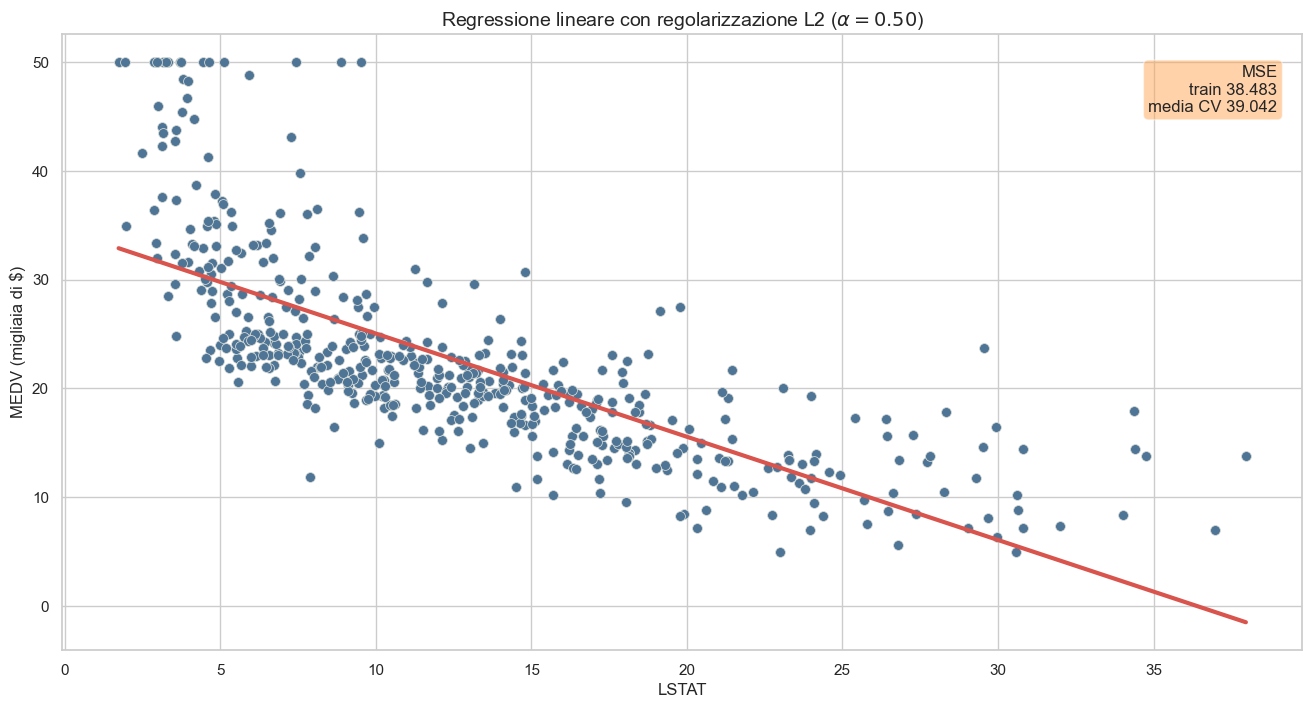

In [36]:
plot_fit(r, X, y, feat, r'Regressione lineare con regolarizzazione L2 ($\alpha={0:.2f}$)'.format(alpha),
         text='MSE\ntrain {0:.3f}\nmedia CV {1:.3f}'.format(mse, mse_cv))

**Elastic Net** combina le due penalità:
$$E(\mathbf{w})=\frac{1}{2n}\sum_{i=1}^n \bigl(y(\mathbf{x}_i;\mathbf{w}) - t_i\bigr)^2+\alpha\gamma\sum_{j\ge1} |w_j|+\frac{\alpha(1-\gamma)}{2}\sum_{j\ge1} w_j^2,$$
dove $\gamma\in[0,1]$ (`l1_ratio` in scikit-learn) regola il peso relativo delle due: $\gamma=1$ dà il Lasso, $\gamma=0$ una Ridge (con la scala del Lasso). Elastic Net è utile quando le feature sono correlate a gruppi: il Lasso tende a sceglierne una sola per gruppo in modo arbitrario, mentre la componente L2 distribuisce il peso tra feature simili.

In [37]:
alpha = 0.5
gamma = 0.3
p = Pipeline([('scaler', StandardScaler()),('regression', ElasticNet(alpha=alpha, l1_ratio=gamma))])
r = p.fit(X, y)
scores = cross_val_score(estimator=p, X=X, y=y, cv=kf10, scoring='neg_mean_squared_error')
mse = mean_squared_error(y, r.predict(X))
mse_cv = -scores.mean()
results.append(['Regression Elastic Net, 1 feature, scaled, CV, alpha=0.5, gamma=0.3', mse, mse_cv])

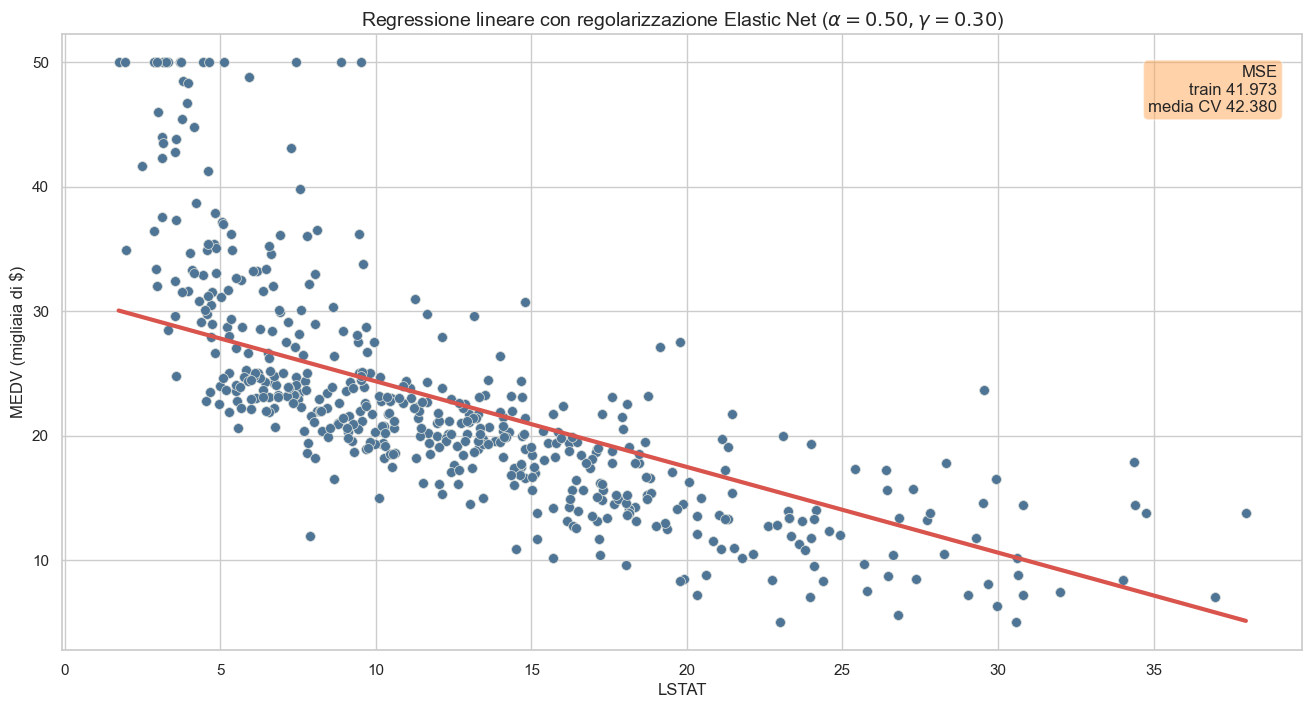

In [38]:
plot_fit(r, X, y, feat, r'Regressione lineare con regolarizzazione Elastic Net ($\alpha={0:.2f}, \gamma={1:.2f}$)'.format(alpha, gamma),
         text='MSE\ntrain {0:.3f}\nmedia CV {1:.3f}'.format(mse, mse_cv))

## Funzioni base polinomiali

Il modello lineare nella feature soffre di bias. Come nelle note, possiamo aumentarne la flessibilità con **funzioni base polinomiali**, $\phi_j(x)=x^j$ per $j=0,\ldots,d$: il modello
$$y(x;\mathbf{w})=\sum_{j=0}^d w_jx^j$$
è non lineare in $x$ ma ancora lineare nei coefficienti, e si apprende con gli stessi metodi. `PolynomialFeatures` di scikit-learn genera le potenze fino al grado dato. Nella pipeline la standardizzazione precede la trasformazione polinomiale: elevare a potenza valori standardizzati, dell'ordine dell'unità, è numericamente molto più stabile che elevare a potenza i valori originali.

In [39]:
deg = 3
pipe_regr = Pipeline([('scaler', StandardScaler()),('bf', PolynomialFeatures(degree=deg)),('regression', LinearRegression())])
r = pipe_regr.fit(X, y)
scores = cross_val_score(estimator=pipe_regr, X=X, y=y, cv=kf10, scoring='neg_mean_squared_error')
mse = mean_squared_error(y, r.predict(X))
mse_cv = -scores.mean()
results.append(['Regression, Polynomial, 1 feature, scaled, degree={0:d}, CV'.format(deg), mse, mse_cv])

Con $d=3$ la curva segue la convessità dei dati, e sia l'errore di training sia quello di cross validation diminuiscono nettamente rispetto alla retta: in questo caso il modello più flessibile riduce il bias senza aumentare troppo la varianza.

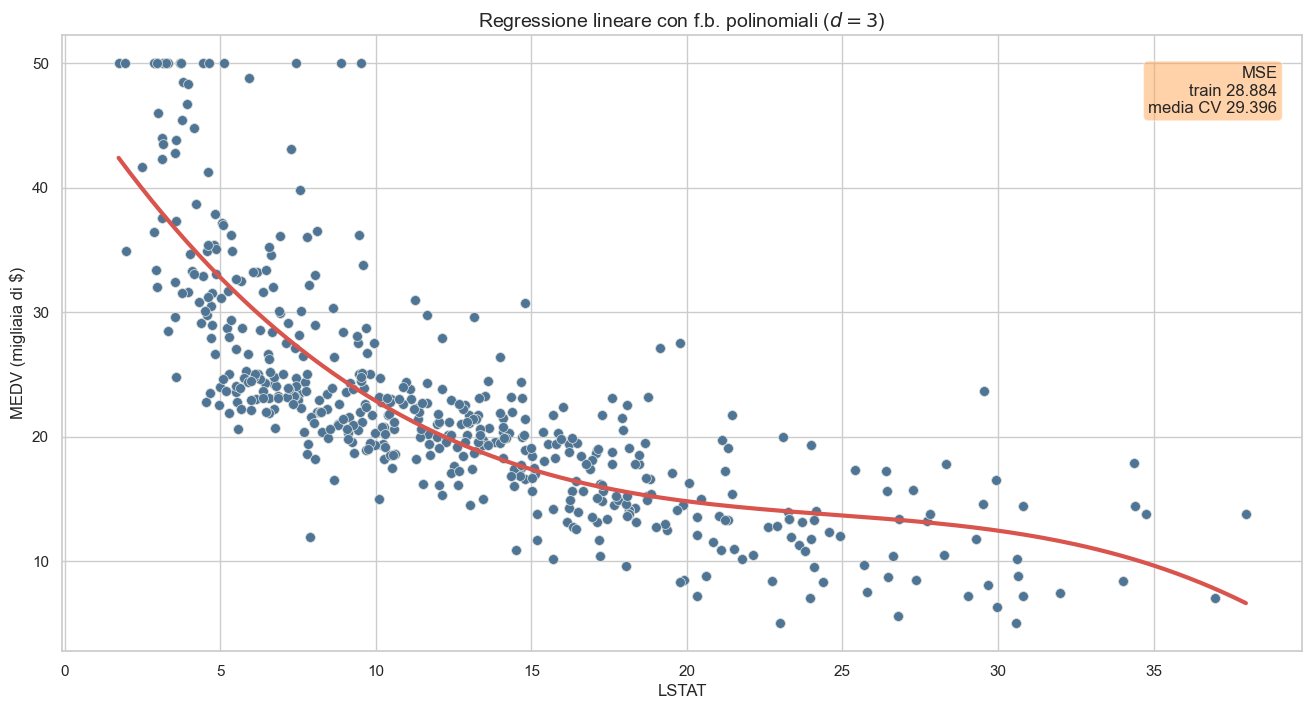

In [40]:
plot_fit(r, X, y, feat, r'Regressione lineare con f.b. polinomiali ($d={0:d}$)'.format(deg),
         text='MSE\ntrain {0:.3f}\nmedia CV {1:.3f}'.format(mse, mse_cv))

Visualizzazione dei **residui** $y_i-t_i$ in funzione delle predizioni $y_i$. Se il modello fosse corretto e il rumore gaussiano con varianza costante, i residui dovrebbero distribuirsi in modo simmetrico attorno a $0$, senza strutture riconoscibili e con la stessa dispersione per ogni valore predetto. Qui si vedono alcune deviazioni dalle ipotesi del modello:

- la distribuzione dei residui è **asimmetrica**, con una lunga coda verso valori negativi: corrisponde a zone il cui prezzo è molto più alto di quanto previsto, tra cui quelle con `MEDV` troncato a $50$;
- la nuvola di punti non è uniforme: la dispersione e il valore medio dei residui variano con il valore predetto, segno che una sola feature non basta a spiegare il prezzo e che il rumore non ha varianza costante (*eteroschedasticità*).

Il modello gaussiano, e quindi la loss quadratica, è sensibile proprio a questo tipo di code: i pochi residui molto grandi pesano molto sulla somma dei quadrati, un problema discusso nelle note a proposito delle loss robuste.

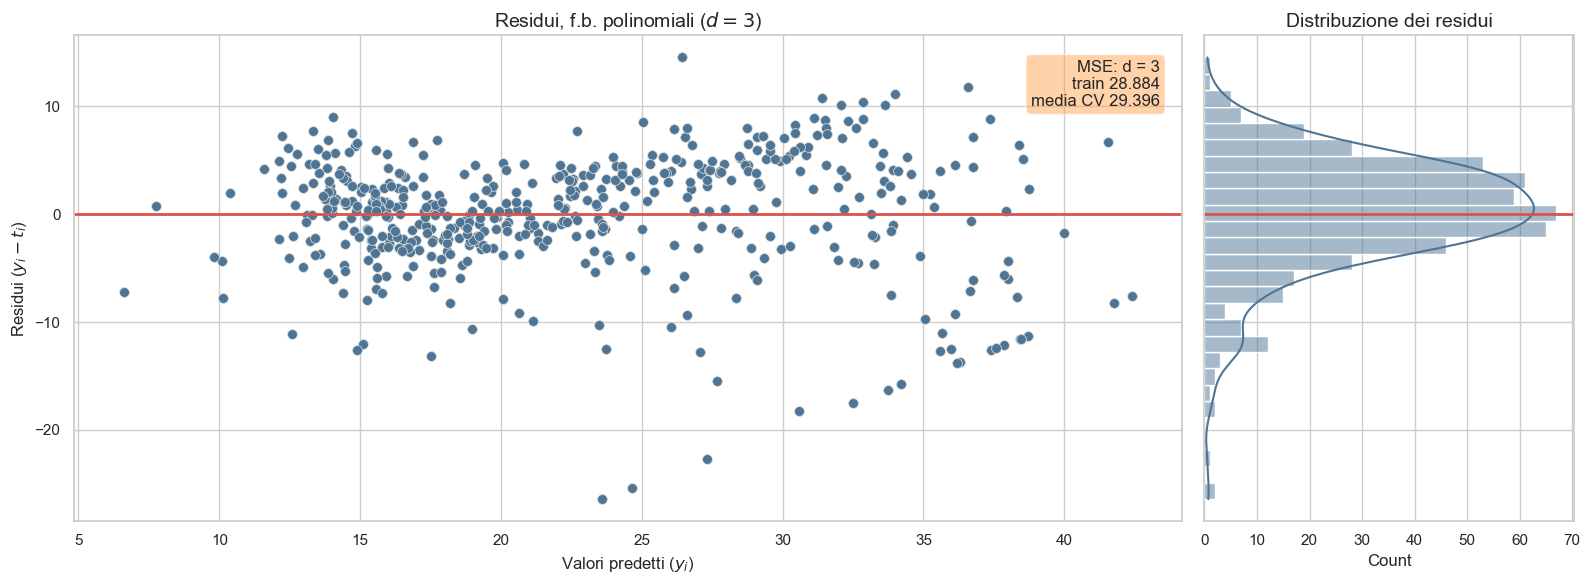

In [41]:
plot_residui(r.predict(X), y, title=r'Residui, f.b. polinomiali ($d={0:d}$)'.format(deg),
             text='MSE: d = {0:d}\ntrain {1:.3f}\nmedia CV {2:.3f}'.format(deg, mse, mse_cv))

Esaminiamo ora come variano l'errore di training e la stima di cross validation al crescere del grado $d$. In teoria l'errore di training non può aumentare con $d$, perché ogni polinomio di grado $d$ è anche un polinomio di grado $d+1$; la stima di cross validation, invece, mostra il compromesso tra bias e varianza: decresce finché il modello impara la struttura dei dati, poi cresce quando inizia a seguire il rumore.

In [42]:
res = []
for deg in range(1, 21):
    r = Pipeline([('scaler', StandardScaler()),('bf', PolynomialFeatures(degree=deg)),('regression', LinearRegression())])
    scores = cross_val_score(estimator=r, X=X, y=y, cv=kf10, scoring='neg_mean_squared_error')
    mse = mean_squared_error(y, r.fit(X, y).predict(X))
    res.append([deg, mse, -scores.mean()])
res_df = pd.DataFrame(res, columns=['grado', 'train', 'CV']).melt(id_vars='grado', var_name='errore', value_name='MSE')

Il grafico usa una scala logaritmica sull'asse verticale, perché per gradi elevati l'errore di cross validation esplode. Due fenomeni contribuiscono:

- l'**estrapolazione**: in ciascun fold il modello è appreso su un sottoinsieme dei dati, e i pochi punti di test agli estremi dell'intervallo di `LSTAT` possono cadere fuori dall'intervallo coperto dal training set, dove un polinomio di grado elevato assume valori enormi;
- il **mal condizionamento numerico**: le colonne $x^j$ per $j$ grande sono quasi linearmente dipendenti, e la matrice $\mathbf{X}^T\mathbf{X}$ delle equazioni normali ha un numero di condizionamento enorme. Lo si vede dall'errore di training, che oltre il grado $12$ circa *aumenta*, contro quanto previsto dalla teoria: non è un effetto statistico, ma la perdita di precisione nel calcolo della soluzione.

Per gradi moderati, invece, l'errore di cross validation è minimo tra $d=5$ e $d=10$ circa, con un guadagno modesto rispetto a $d=3$.

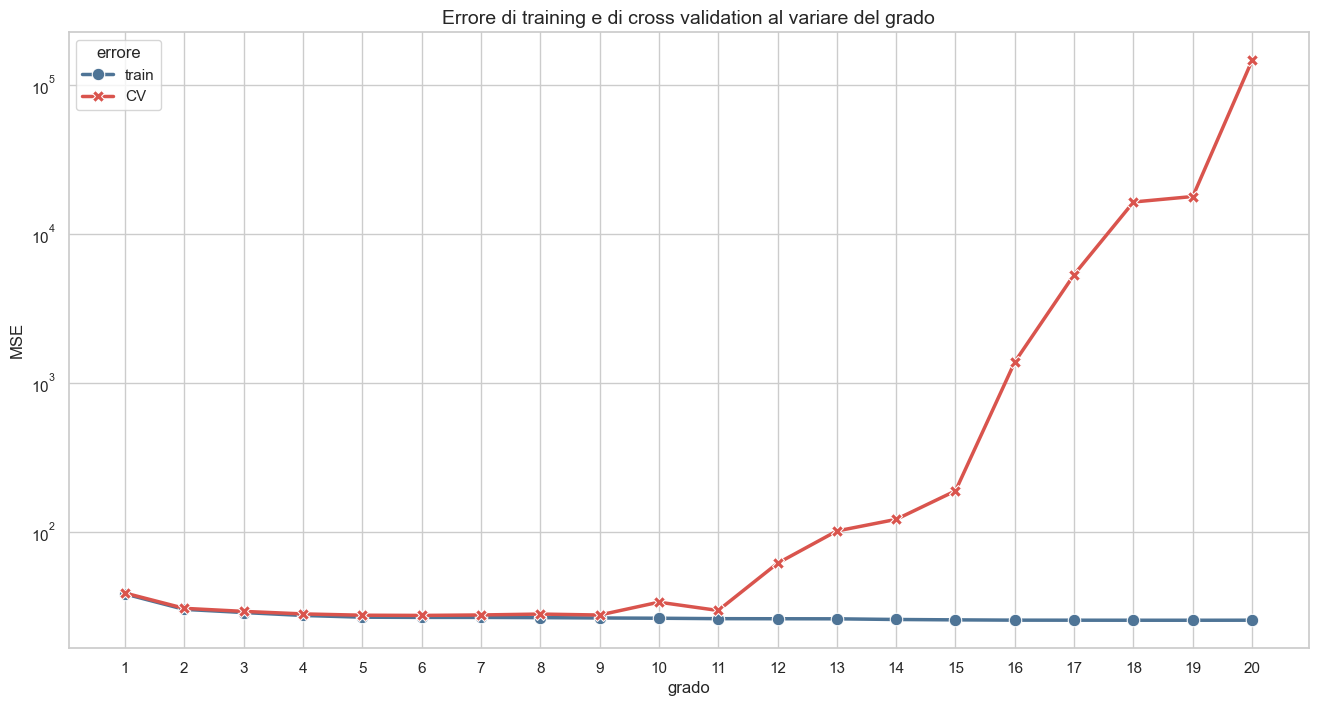

In [43]:
fig, ax = plt.subplots(figsize=(16, 8))
sns.lineplot(data=res_df, x='grado', y='MSE', hue='errore', style='errore', markers=True, dashes=False,
             palette=[colors[8], colors[2]], linewidth=2.5, markersize=9, ax=ax)
ax.set_yscale('log')
ax.set_xticks(range(1, 21))
ax.set_title('Errore di training e di cross validation al variare del grado')
plt.show()

Combiniamo ora le funzioni base polinomiali con la regolarizzazione L1. La penalità limita la grandezza dei coefficienti delle potenze, e quindi le oscillazioni del polinomio: possiamo usare un grado più alto senza che la curva diventi instabile.

In [44]:
alpha = 0.1
deg = 3
pipe_regr = Pipeline([('scaler', StandardScaler()),('bf', PolynomialFeatures(degree=deg)),('regression', Lasso(alpha=alpha, max_iter=100000))])
r = pipe_regr.fit(X, y)
scores = cross_val_score(estimator=pipe_regr, X=X, y=y, cv=kf10, scoring='neg_mean_squared_error')
mse = mean_squared_error(y, r.predict(X))
mse_cv = -scores.mean()
results.append(['Regression L1, Polynomial, 1 feature, scaled, degree={0:d}, alpha={1:.1f}, CV'.format(deg, alpha), mse, mse_cv])
print('coefficienti:', np.round(r.named_steps['regression'].coef_, 3))

coefficienti: [ 0.    -7.472  3.478 -0.676]


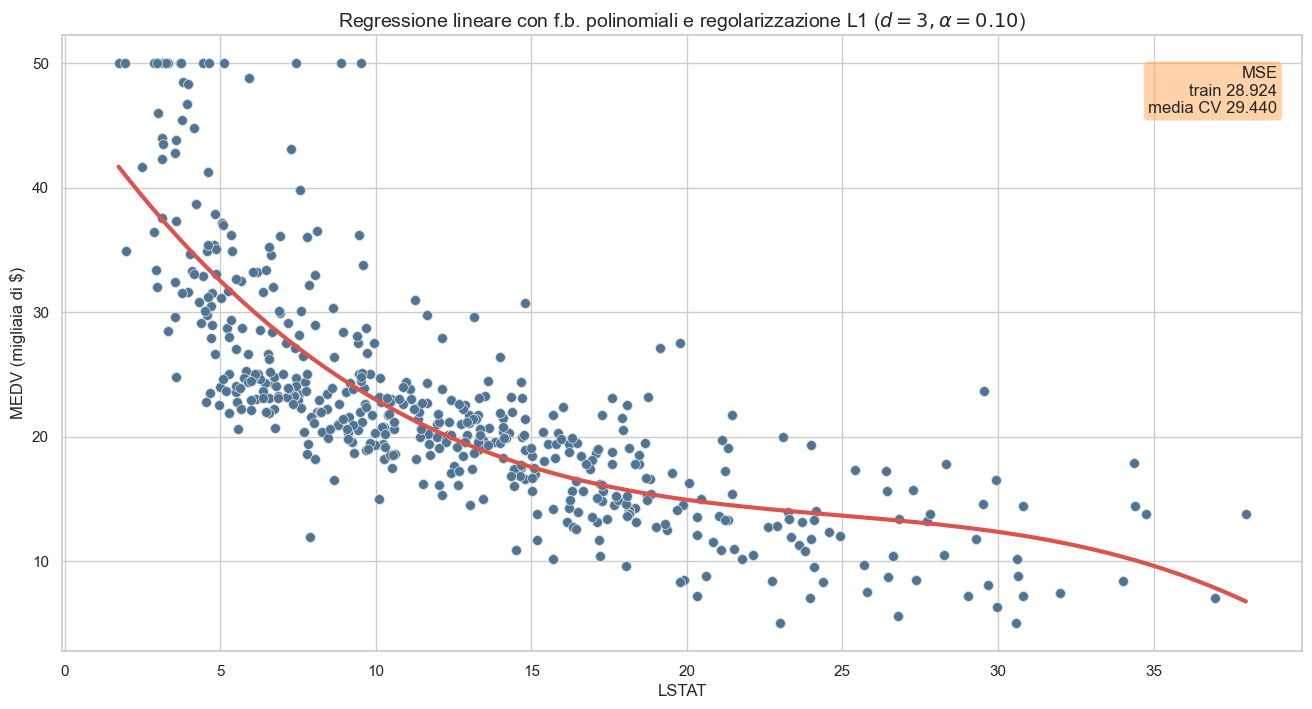

In [45]:
plot_fit(r, X, y, feat, r'Regressione lineare con f.b. polinomiali e regolarizzazione L1 ($d={0:d}, \alpha={1:.2f}$)'.format(deg, alpha),
         text='MSE\ntrain {0:.3f}\nmedia CV {1:.3f}'.format(mse, mse_cv))

Ripetiamo l'analisi al variare del grado, questa volta con la regolarizzazione L1: l'errore di cross validation resta sotto controllo anche per gradi elevati, perché il Lasso annulla o riduce i coefficienti delle potenze più alte.

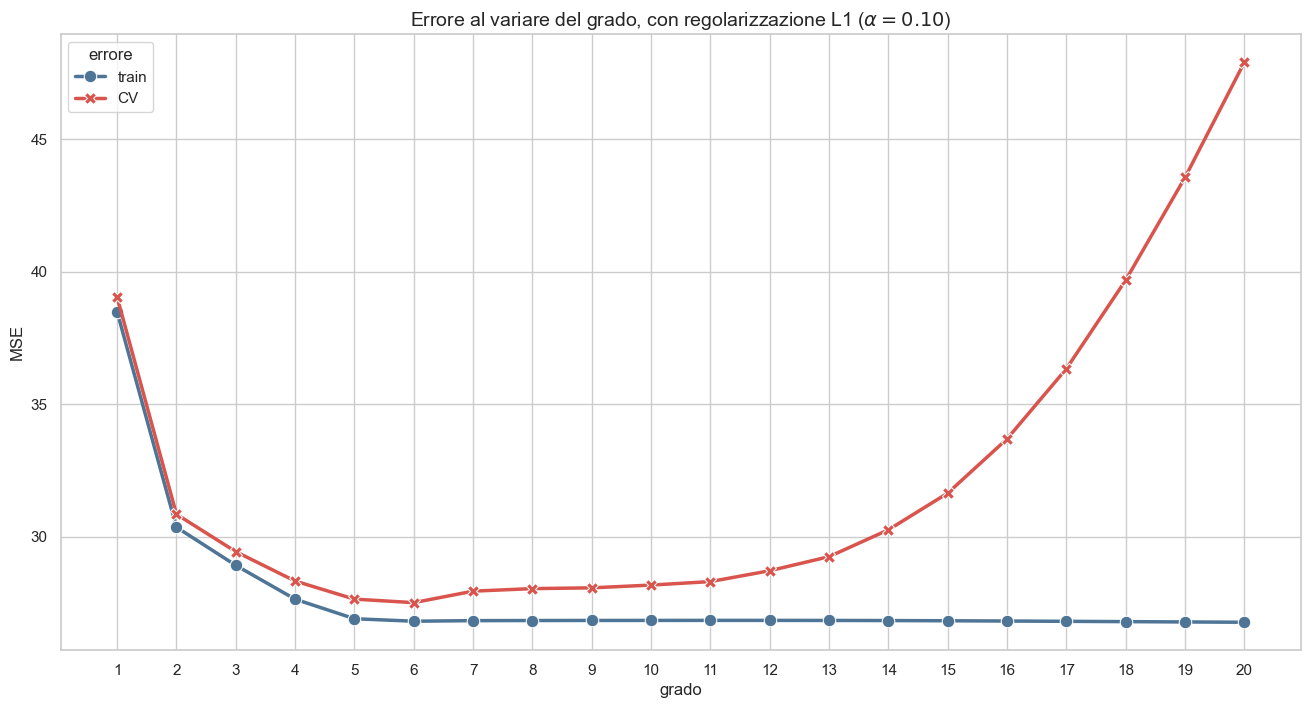

In [46]:
res = []
for deg in range(1, 21):
    r = Pipeline([('scaler', StandardScaler()),('bf', PolynomialFeatures(degree=deg)),('regression', Lasso(alpha=alpha, max_iter=100000))])
    scores = cross_val_score(estimator=r, X=X, y=y, cv=kf10, scoring='neg_mean_squared_error')
    mse = mean_squared_error(y, r.fit(X, y).predict(X))
    res.append([deg, mse, -scores.mean()])
res_df = pd.DataFrame(res, columns=['grado', 'train', 'CV']).melt(id_vars='grado', var_name='errore', value_name='MSE')

fig, ax = plt.subplots(figsize=(16, 8))
sns.lineplot(data=res_df, x='grado', y='MSE', hue='errore', style='errore', markers=True, dashes=False,
             palette=[colors[8], colors[2]], linewidth=2.5, markersize=9, ax=ax)
ax.set_xticks(range(1, 21))
ax.set_title(r'Errore al variare del grado, con regolarizzazione L1 ($\alpha={0:.2f}$)'.format(alpha))
plt.show()

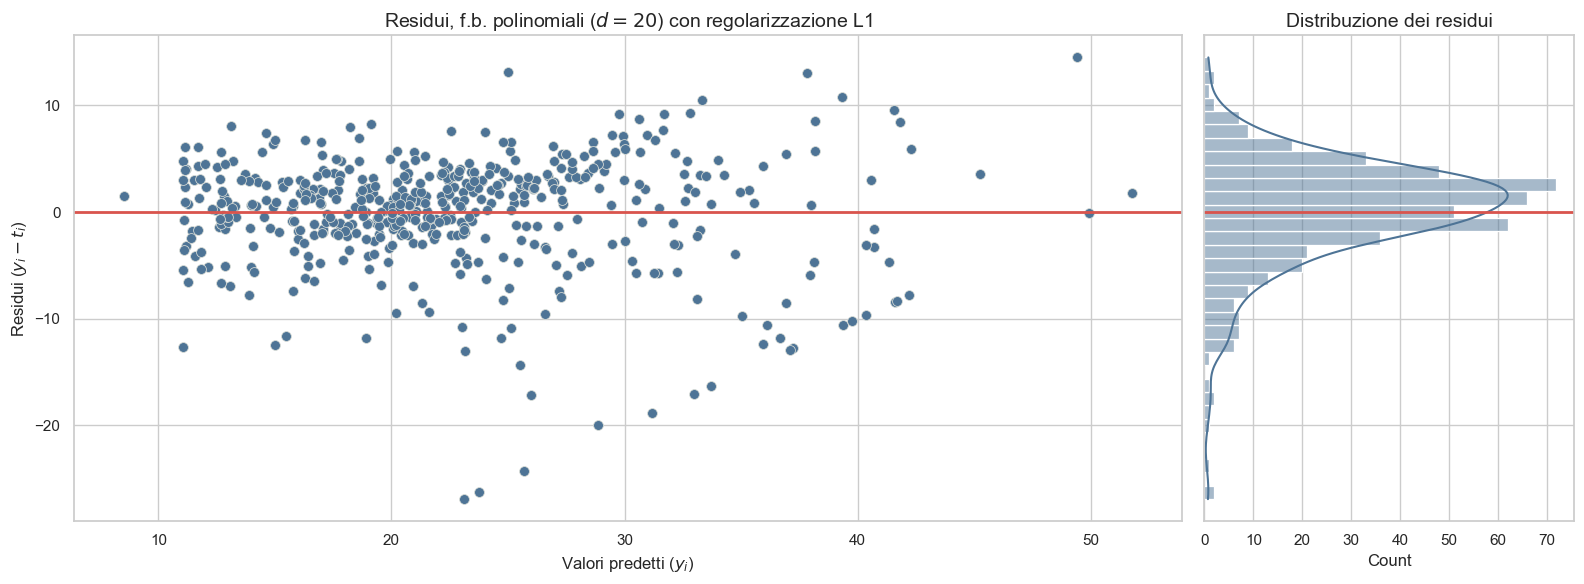

In [47]:
plot_residui(r.predict(X), y, title=r'Residui, f.b. polinomiali ($d=20$) con regolarizzazione L1')

## Regressione su tutte le feature

Usiamo ora tutte le $13$ feature. Il modello ha più informazione a disposizione, ma anche più coefficienti da stimare, e alcune feature sono fortemente correlate tra loro.

In [48]:
X = df[df.columns[:-1]].values
y = df[df.columns[-1]].values

In [49]:
r = LinearRegression()
r.fit(X, y)
print('MSE (training): {0:.3f}'.format(mean_squared_error(y, r.predict(X))))

MSE (training): 21.895


Coefficienti del modello appreso sulle feature originali: i loro valori dipendono dalle unità di misura delle feature (ad esempio il coefficiente di `NOX`, misurato in parti per $10$ milioni, è grande perché `NOX` varia su un intervallo piccolo), e non sono quindi confrontabili tra loro.

In [50]:
coef = pd.Series(r.coef_, index=df.columns[:-1])
coef.round(3)

CRIM       -0.108
ZN          0.046
INDUS       0.021
CHAS        2.687
NOX       -17.767
RM          3.810
AGE         0.001
DIS        -1.476
RAD         0.306
TAX        -0.012
PTRATIO    -0.953
B           0.009
LSTAT      -0.525
dtype: float64

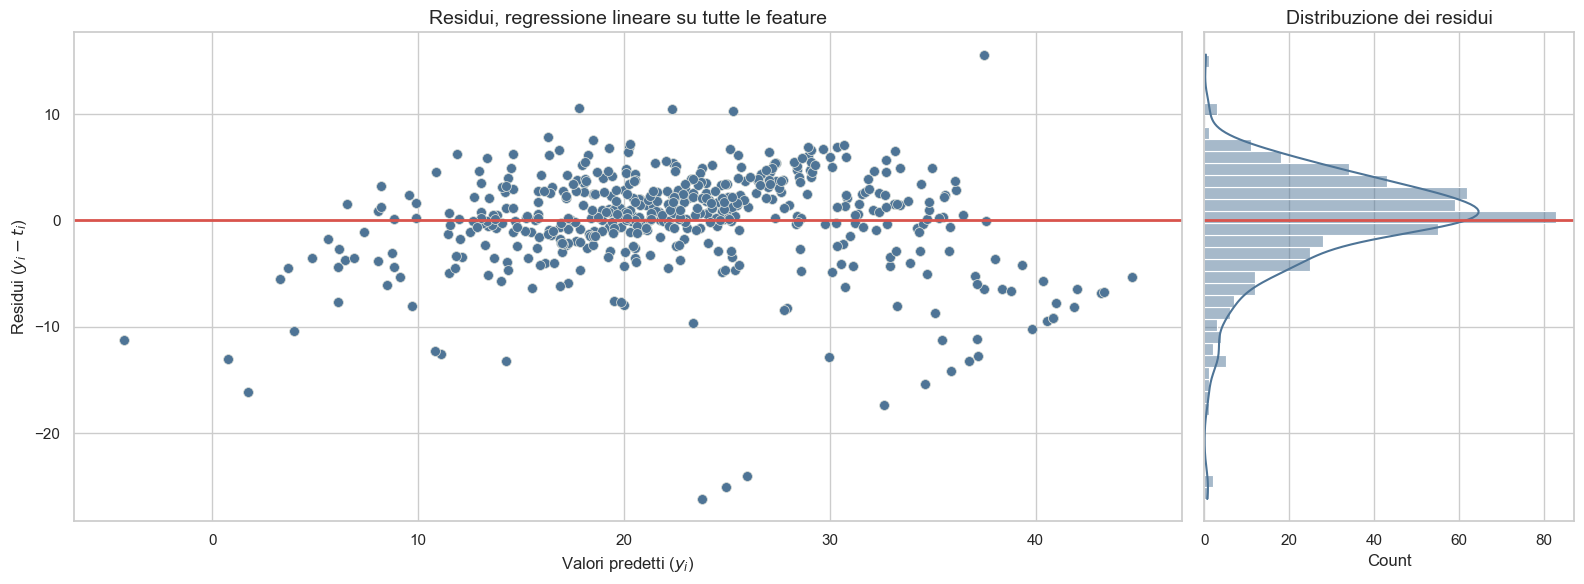

In [51]:
plot_residui(r.predict(X), y, title='Residui, regressione lineare su tutte le feature')

Con le feature standardizzate le predizioni (e quindi l'errore) sono le stesse, ma i coefficienti diventano confrontabili: ciascuno misura l'effetto sul prezzo di una variazione di una deviazione standard della feature corrispondente, a parità delle altre. Le feature con il peso maggiore in valore assoluto sono `LSTAT`, `DIS`, `RM` e `RAD`.

Si noti che `DIS` ha un coefficiente negativo, mentre la sua correlazione con `MEDV` è positiva: a parità delle altre feature (in particolare di `NOX` e `INDUS`, con cui è fortemente correlata), la distanza dai centri di lavoro riduce il prezzo. I coefficienti di un modello con feature correlate descrivono effetti *condizionati*, e possono avere segno diverso da quello della relazione marginale.

MSE (training): 21.895


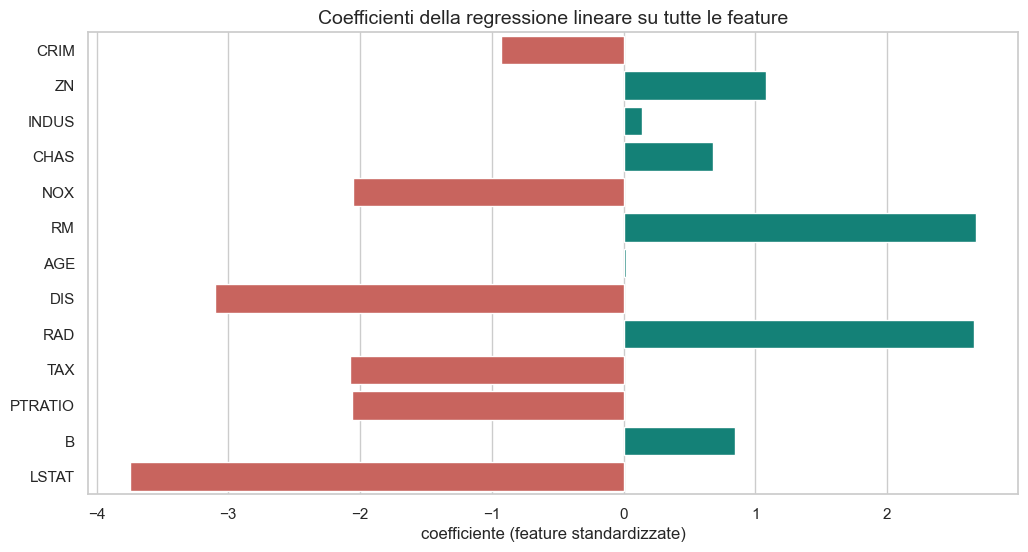

In [52]:
r = Pipeline([('scaler', StandardScaler()),('regression', LinearRegression())])
r.fit(X, y)
print('MSE (training): {0:.3f}'.format(mean_squared_error(y, r.predict(X))))
coef_std = pd.Series(r.named_steps['regression'].coef_, index=df.columns[:-1])

plt.figure(figsize=(12, 6))
sns.barplot(x=coef_std.values, y=coef_std.index, hue=coef_std.values > 0, palette={True: colors[6], False: colors[2]},
            legend=False, orient='h')
plt.xlabel('coefficiente (feature standardizzate)')
plt.ylabel('')
plt.title('Coefficienti della regressione lineare su tutte le feature')
plt.show()

Applichiamo la cross validation ai diversi modelli, con gli stessi fold per tutti in modo che i confronti siano equi. Si noti che la deviazione standard degli errori sui fold è dello stesso ordine delle differenze tra i modelli: con un dataset di queste dimensioni, piccole differenze nella stima dell'errore non sono significative.

In [53]:
modelli = {
    'Linear': LinearRegression(),
    'Lasso, alpha=0.5': Lasso(alpha=0.5),
    'Ridge, alpha=10': Ridge(alpha=10),
    'Elastic Net, alpha=0.5, gamma=0.3': ElasticNet(alpha=0.5, l1_ratio=0.3),
}
cv_scores = []
for nome, modello in modelli.items():
    r = Pipeline([('scaler', StandardScaler()),('regression', modello)])
    scores = -cross_val_score(estimator=r, X=X, y=y, cv=kf5, scoring='neg_mean_squared_error')
    mse = mean_squared_error(y, r.fit(X, y).predict(X))
    results.append(['Regression {0}, all features, scaled, CV'.format(nome), mse, scores.mean()])
    print('{0:35s} MSE per fold {1}, media {2:.3f}, dev.standard {3:.3f}'.format(nome, np.round(scores, 2), scores.mean(), scores.std()))
    cv_scores += [[nome, k, s] for k, s in enumerate(scores)]
cv_scores = pd.DataFrame(cv_scores, columns=['modello', 'fold', 'MSE'])

Linear                              MSE per fold [33.45 18.66 21.23 29.22 16.57], media 23.828, dev.standard 6.446
Lasso, alpha=0.5                    MSE per fold [39.74 19.29 22.13 35.17 22.45], media 27.756, dev.standard 8.126
Ridge, alpha=10                     MSE per fold [34.27 18.03 21.02 29.68 16.42], media 23.883, dev.standard 6.922
Elastic Net, alpha=0.5, gamma=0.3   MSE per fold [40.52 18.74 20.82 34.47 23.58], media 27.628, dev.standard 8.425


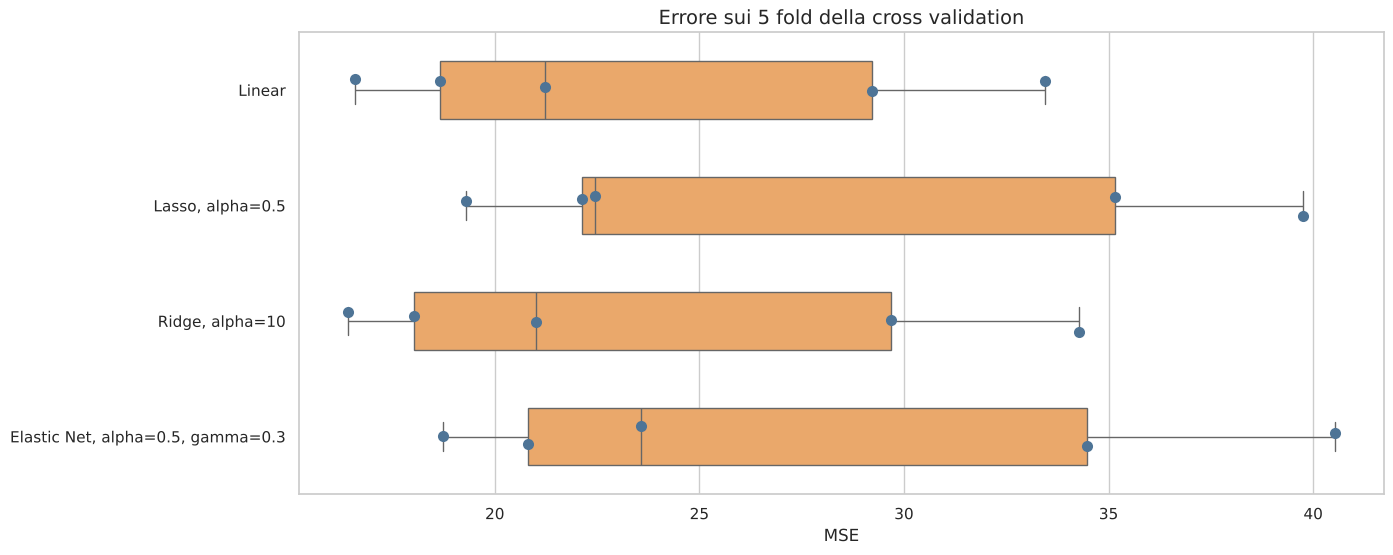

In [53]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=cv_scores, x='MSE', y='modello', color=colors[0], width=.5)
sns.stripplot(data=cv_scores, x='MSE', y='modello', color=colors[8], size=8)
plt.ylabel('')
plt.title('Errore sui 5 fold della cross validation')
plt.show()

### Percorsi di regolarizzazione

Per capire come la regolarizzazione agisce sui coefficienti, esaminiamo il loro valore al variare di $\alpha$ (il *percorso di regolarizzazione*), per Lasso e Ridge. Le due penalità si comportano in modo molto diverso:

- nel Lasso, al crescere di $\alpha$ i coefficienti si annullano uno dopo l'altro, e per $\alpha$ abbastanza grande restano solo poche feature: è la **sparsità**, che deriva dalla geometria della regione di vincolo L1, come discusso nelle note;
- nella Ridge, i coefficienti si riducono gradualmente verso zero senza annullarsi.

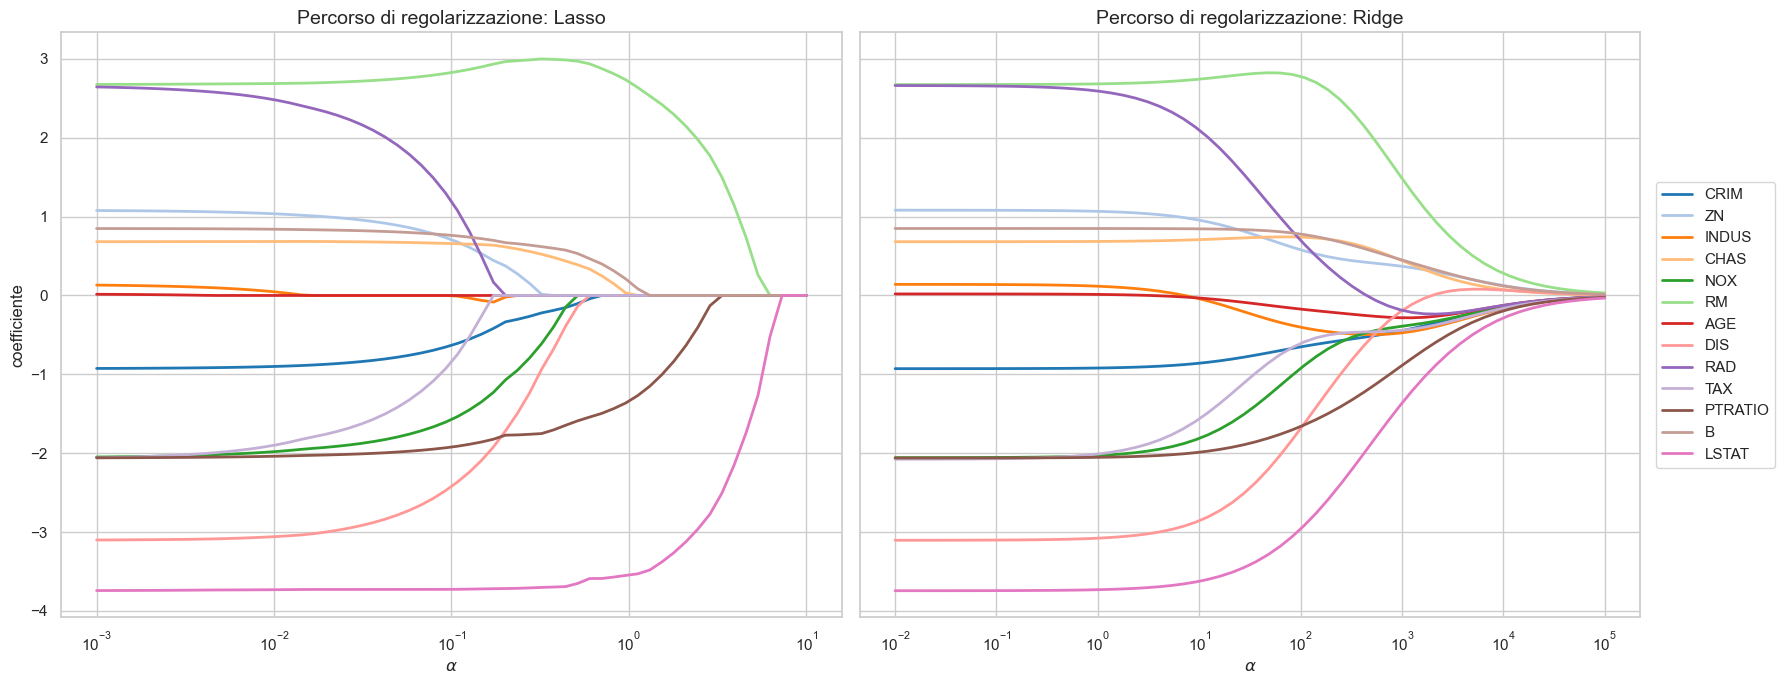

In [54]:
alphas_lasso = np.logspace(-3, 1, 60)
alphas_ridge = np.logspace(-2, 5, 60)
paths = []
for name, est, alphas in (('Lasso', Lasso, alphas_lasso), ('Ridge', Ridge, alphas_ridge)):
    for a in alphas:
        r = Pipeline([('scaler', StandardScaler()),('regression', est(alpha=a))]).fit(X, y)
        for f_, c_ in zip(df.columns[:-1], r.named_steps['regression'].coef_):
            paths.append([name, a, f_, c_])
paths = pd.DataFrame(paths, columns=['modello', 'alpha', 'feature', 'coefficiente'])

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
for ax, name in zip(axes, ('Lasso', 'Ridge')):
    sns.lineplot(data=paths[paths.modello == name], x='alpha', y='coefficiente', hue='feature', palette='tab20',
                 linewidth=2, legend=(name == 'Ridge'), ax=ax)
    ax.set_xscale('log')
    ax.set_xlabel(r'$\alpha$')
    ax.set_title('Percorso di regolarizzazione: ' + name)
axes[1].legend(loc='center left', bbox_to_anchor=(1.01, .5))
plt.tight_layout()
plt.show()

LassoCV effettua la ricerca del miglior valore per $\alpha$ mediante cross validation, in modo efficiente: calcola la soluzione per una sequenza decrescente di valori di $\alpha$, usando ogni soluzione come punto di partenza per la successiva. Il modello restituito è poi riaddestrato su tutti i dati con il valore di $\alpha$ selezionato.

Per valutare correttamente l'errore di un modello il cui iperparametro è scelto con la cross validation, occorre una **cross validation annidata**: passando l'intera pipeline con `LassoCV` a `cross_val_score`, la scelta di $\alpha$ viene ripetuta all'interno di ciascun fold esterno, senza mai usare i dati del fold di test.

In [55]:
pipe_regr = Pipeline([('scaler', StandardScaler()),('regression', LassoCV(cv=kf10, max_iter=100000))])
r = pipe_regr.fit(X, y)
best_alpha = pipe_regr.named_steps['regression'].alpha_
# cross validation annidata: alpha viene riselezionato in ogni fold esterno
scores = cross_val_score(estimator=pipe_regr, X=X, y=y, cv=kf5, scoring='neg_mean_squared_error')
print(r'Miglior valore di alpha: {0:.4f}'.format(best_alpha))
print('MSE (CV annidata): {0:.3f}'.format(-scores.mean()))
results.append(['Regression LassoCV, all features, scaled, nested CV', mean_squared_error(y, r.predict(X)), -scores.mean()])

Miglior valore di alpha: 0.0207
MSE (CV annidata): 23.806


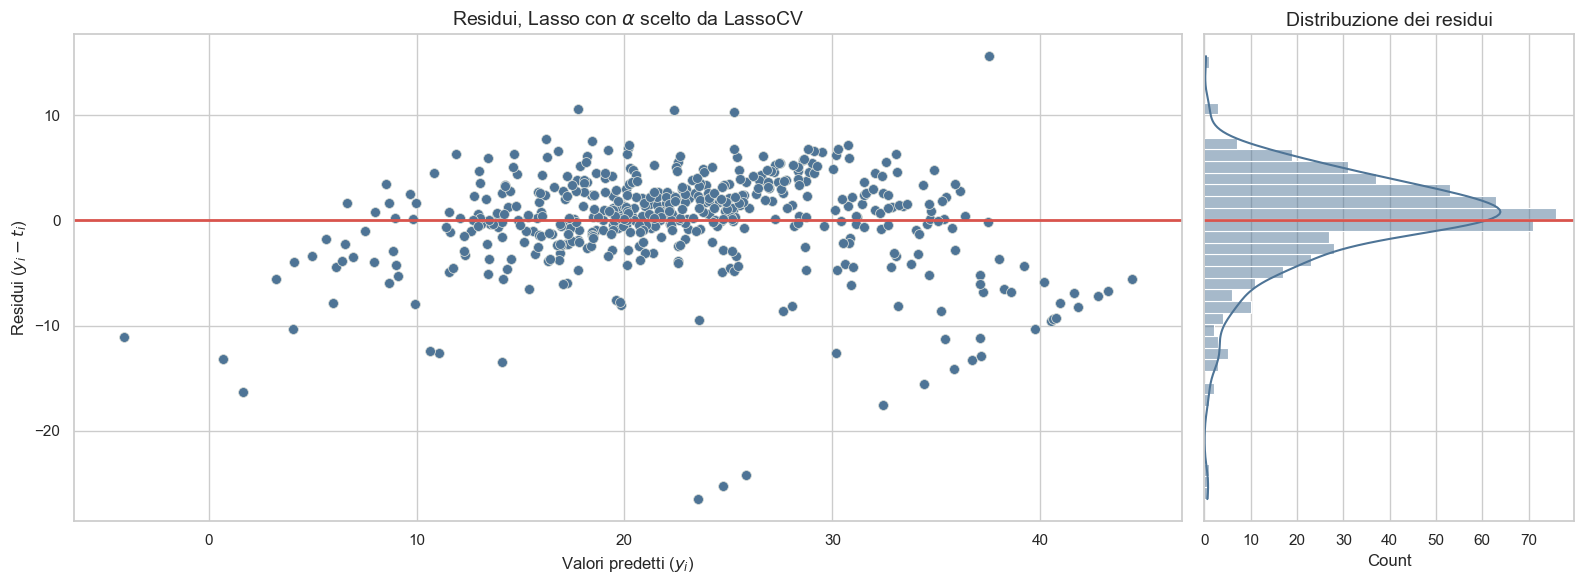

In [56]:
plot_residui(r.predict(X), y, title=r'Residui, Lasso con $\alpha$ scelto da LassoCV')

Lo stesso per la Ridge con RidgeCV. Senza l'argomento `cv`, RidgeCV usa la **leave-one-out cross validation**, che per la Ridge si calcola in forma chiusa, con il costo di un solo addestramento: è il motivo per cui RidgeCV è molto veloce anche con molti valori di $\alpha$.

In [57]:
pipe_regr = Pipeline([('scaler', StandardScaler()),('regression', RidgeCV(alphas=np.logspace(-3, 3, 100)))])
r = pipe_regr.fit(X, y)
best_alpha = pipe_regr.named_steps['regression'].alpha_
scores = cross_val_score(estimator=pipe_regr, X=X, y=y, cv=kf5, scoring='neg_mean_squared_error')
print(r'Miglior valore di alpha: {0:.4f}'.format(best_alpha))
print('MSE (CV annidata): {0:.3f}'.format(-scores.mean()))
results.append(['Regression RidgeCV, all features, scaled, nested CV', mean_squared_error(y, r.predict(X)), -scores.mean()])

Miglior valore di alpha: 4.9770
MSE (CV annidata): 23.882


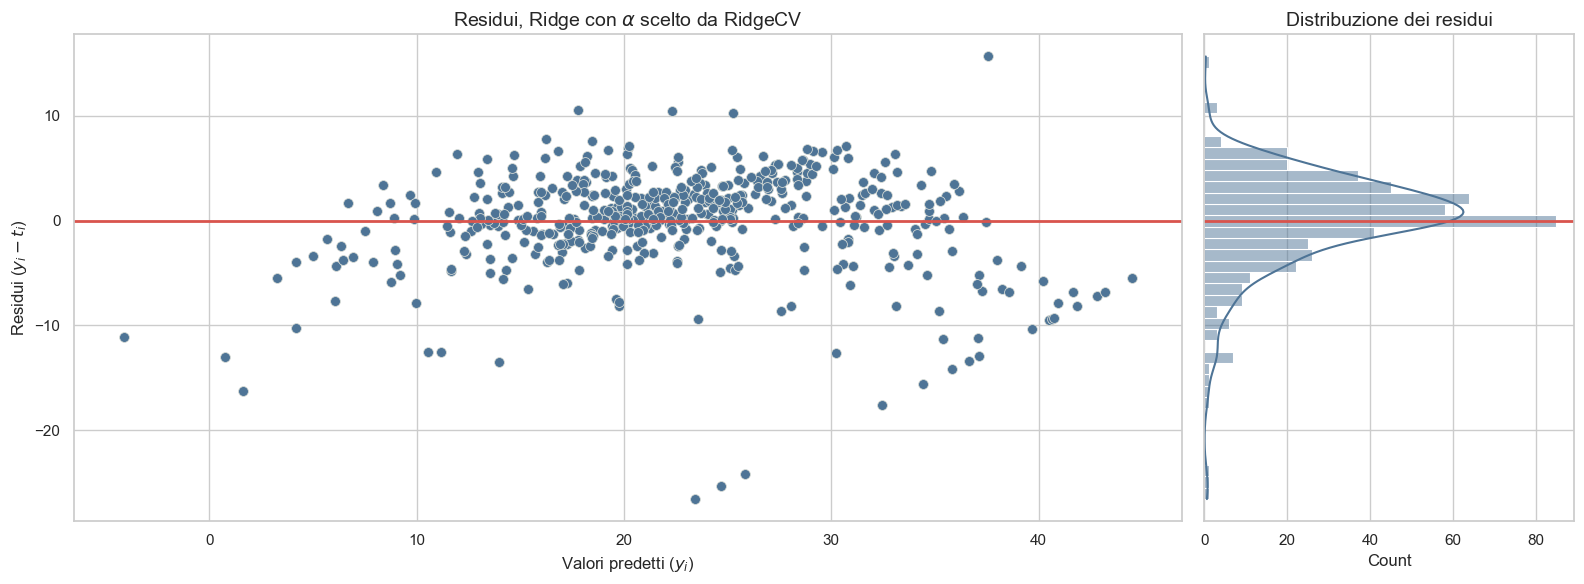

In [58]:
plot_residui(r.predict(X), y, title=r'Residui, Ridge con $\alpha$ scelto da RidgeCV')

## Model selection

In questa sezione confrontiamo tre modi di scegliere gli iperparametri, su tutte le feature: una ricerca su griglia implementata direttamente, `GridSearchCV` e le classi specializzate `LassoCV` e `RidgeCV`. Come griglia di valori usiamo una scala **logaritmica**: l'effetto di $\alpha$ dipende dal suo ordine di grandezza, e una griglia lineare spreca la maggior parte dei punti in una regione in cui l'errore varia poco.

In [59]:
X = np.array(df[df.columns[:-1]])
y = np.array(df[df.columns[-1]])

### Lasso

Ricerca su griglia dei valori di $\alpha$, con la cross validation implementata direttamente. Per ogni $\alpha$ sommiamo gli errori quadratici su tutti i fold di test e dividiamo per il numero di elementi: poiché ogni elemento appartiene a esattamente un fold di test, il risultato è il MSE medio su tutto il dataset.

In [60]:
domain = np.logspace(-3, 1, 50)
scores = []
# considera tutti i valori di alpha in domain
for a in domain:
    # definisce modello con Lasso
    p = Pipeline([('scaler', StandardScaler()),('regression', Lasso(alpha=a, max_iter=100000))])
    xval_err = 0
    # per ogni coppia train-test valuta l'errore sul test set del modello istanziato sulla base del training set
    for k, (train_index, test_index) in enumerate(kf10.split(X, y)):
        p.fit(X[train_index], y[train_index])
        y1 = p.predict(X[test_index])
        err = y1 - y[test_index]
        xval_err += np.dot(err, err)
    # calcola errore medio 
    score = xval_err/X.shape[0]
    scores.append([a, score])
scores = np.array(scores)

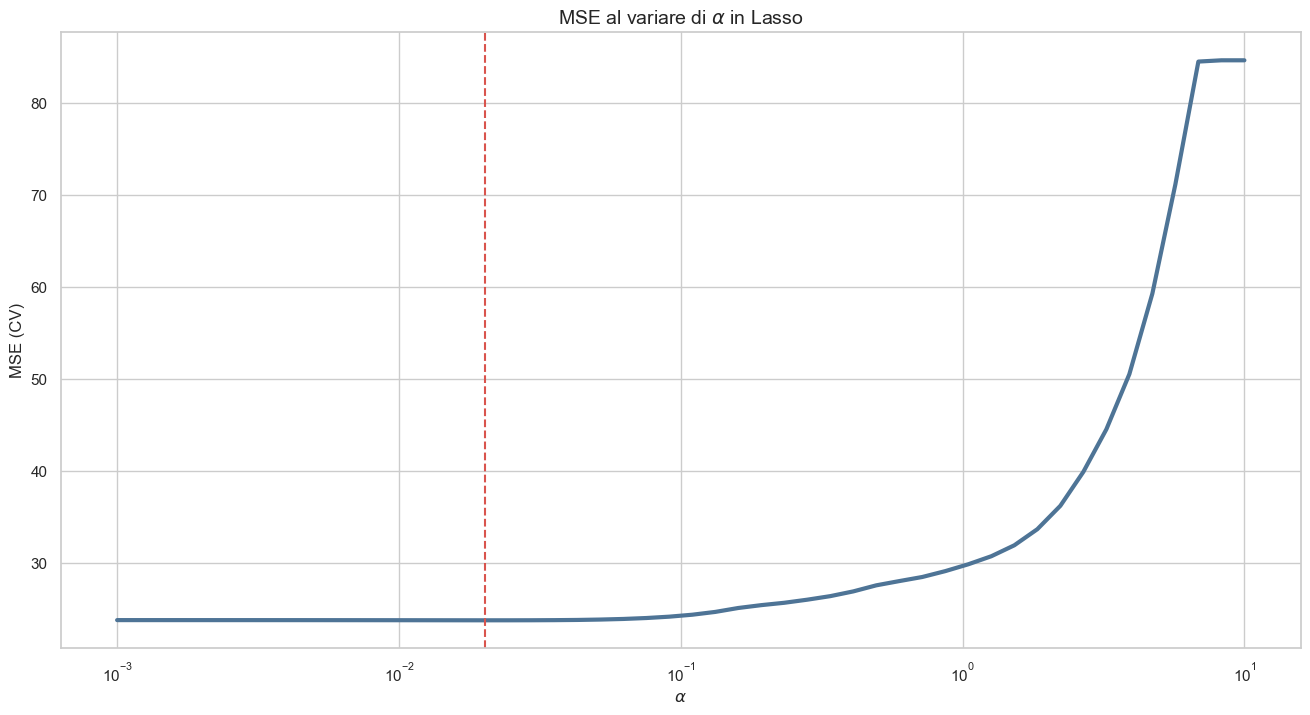

Miglior valore per alpha: 0.02024. MSE=23.783


In [61]:
min_index = np.argmin(scores[:,1])
fig, ax = plt.subplots(figsize=(16, 8))
sns.lineplot(x=scores[:,0], y=scores[:,1], color=colors[8], linewidth=3, ax=ax)
ax.axvline(scores[min_index,0], color=colors[2], ls='--')
ax.set_xscale('log')
ax.set_xlabel(r'$\alpha$')
ax.set_ylabel('MSE (CV)')
ax.set_title(r'MSE al variare di $\alpha$ in Lasso')
plt.show()
print('Miglior valore per alpha: {0:.5f}. MSE={1:.3f}'.format(scores[min_index,0], scores[min_index,1]))

La curva è piatta per $\alpha$ piccolo, dove il Lasso coincide con la regressione lineare, e cresce rapidamente quando $\alpha$ diventa abbastanza grande da annullare feature utili. Il minimo è poco pronunciato: su questo dataset la regolarizzazione migliora di poco la stima dell'errore, perché con $506$ elementi e $13$ feature la regressione lineare non è in grave overfitting.

**Attenzione al ruolo del mescolamento.** Con fold consecutivi, come quelli che si ottengono passando `cv=10` invece di un `KFold` con `shuffle=True`, il valore di $\alpha$ selezionato e l'errore stimato cambiano molto: il fold di test contiene zone sistematicamente diverse da quelle di training, e la cross validation "premia" una regolarizzazione più forte, che rende il modello meno dipendente dalle peculiarità del training set. È un esempio di come un difetto nel protocollo di valutazione si traduca in una scelta sbagliata degli iperparametri.

In [62]:
for nome, cv in (('fold consecutivi', 10), ('fold mescolati', kf10)):
    clf = GridSearchCV(Pipeline([('scaler', StandardScaler()),('regression', Lasso(max_iter=100000))]),
                       {'regression__alpha': domain}, cv=cv, scoring='neg_mean_squared_error').fit(X, y)
    print('{0:17s}: alpha = {1:.4f}, MSE = {2:.3f}'.format(nome, clf.best_params_['regression__alpha'], -clf.best_score_))

fold consecutivi : alpha = 0.1931, MSE = 33.884
fold mescolati   : alpha = 0.0202, MSE = 23.777


Utilizzo di GridSearchCV, che effettua la stessa ricerca su griglia (anche su più iperparametri contemporaneamente) e restituisce il modello migliore riaddestrato su tutti i dati.

In [63]:
param_grid = [{'regression__alpha': domain}]
p = Pipeline([('scaler', StandardScaler()),('regression', Lasso(max_iter=100000))])

clf = GridSearchCV(p, param_grid, cv=kf10, scoring='neg_mean_squared_error')
clf = clf.fit(X, y)
sc = -clf.cv_results_['mean_test_score']
sd = clf.cv_results_['std_test_score']

GridSearchCV restituisce anche la deviazione standard dell'errore sui fold, che riportiamo come banda attorno alla media: le variazioni della curva in prossimità del minimo sono molto più piccole della variabilità tra i fold.

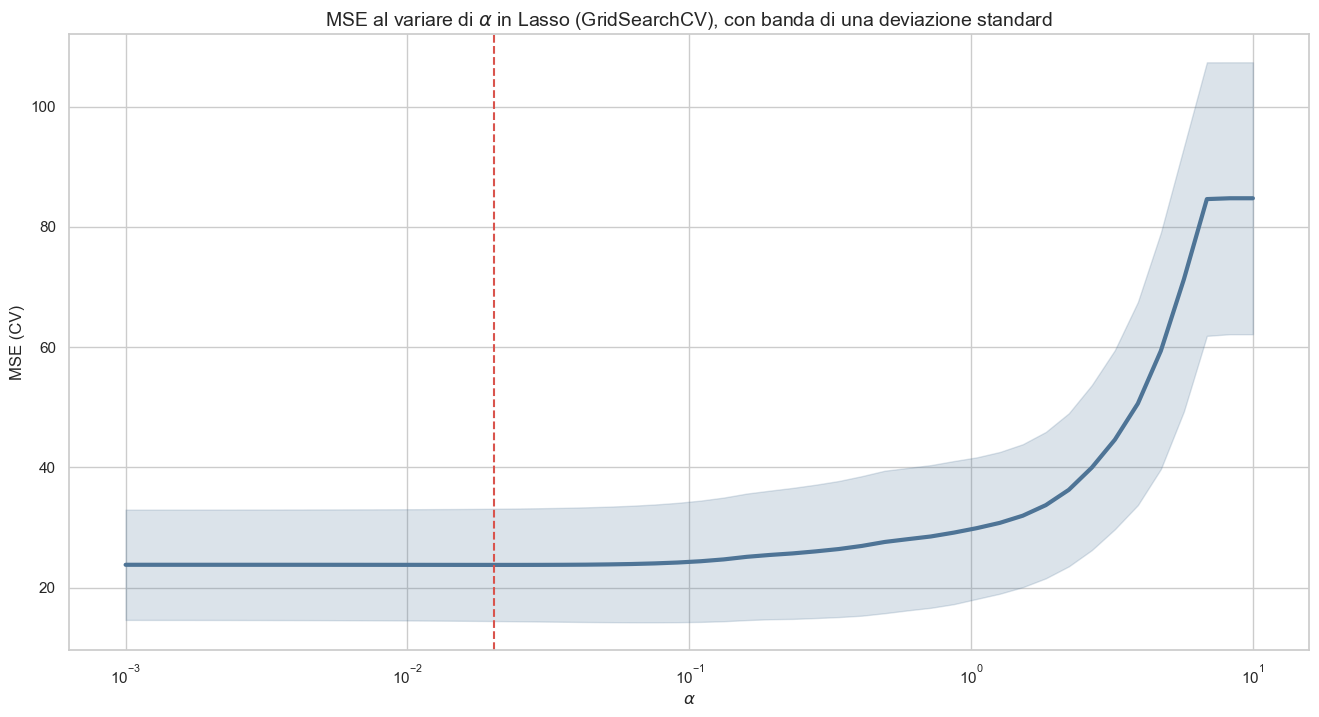

Miglior valore per alpha: 0.02024. MSE=23.777


In [64]:
min_index = np.argmin(sc)
fig, ax = plt.subplots(figsize=(16, 8))
sns.lineplot(x=domain, y=sc, color=colors[8], linewidth=3, ax=ax)
ax.fill_between(domain, sc-sd, sc+sd, color=colors[8], alpha=.2)
ax.axvline(domain[min_index], color=colors[2], ls='--')
ax.set_xscale('log')
ax.set_xlabel(r'$\alpha$')
ax.set_ylabel('MSE (CV)')
ax.set_title(r'MSE al variare di $\alpha$ in Lasso (GridSearchCV), con banda di una deviazione standard')
plt.show()
print('Miglior valore per alpha: {0:.5f}. MSE={1:.3f}'.format(domain[min_index], sc[min_index]))

Utilizzo di LassoCV, che ricerca il miglior valore di $\alpha$ valutando lo score su un insieme di possibili valori mediante cross validation. L'attributo `mse_path_` contiene l'errore per ogni valore di $\alpha$ e per ogni fold.

In [65]:
p = Pipeline([('scaler', StandardScaler()),('regression', LassoCV(cv=kf10, alphas=domain, max_iter=100000))])
r = p.fit(X, y)
reg = r.named_steps['regression']
scores = np.mean(reg.mse_path_, axis=1)

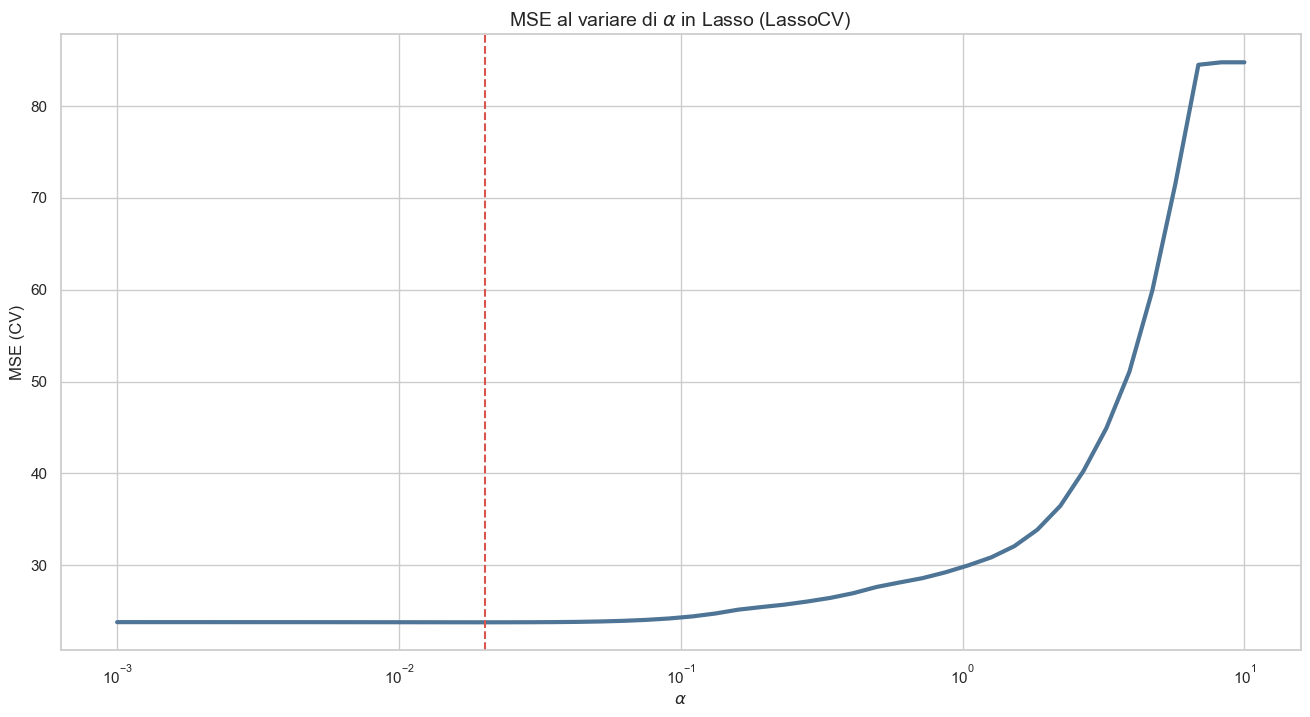

Miglior valore di alpha: 0.02024, MSE: 23.780


In [66]:
fig, ax = plt.subplots(figsize=(16, 8))
sns.lineplot(x=reg.alphas_, y=scores, color=colors[8], linewidth=3, ax=ax)
ax.axvline(reg.alpha_, color=colors[2], ls='--')
ax.set_xscale('log')
ax.set_xlabel(r'$\alpha$')
ax.set_ylabel('MSE (CV)')
ax.set_title(r'MSE al variare di $\alpha$ in Lasso (LassoCV)')
plt.show()
best_alpha = reg.alpha_
i, = np.where(reg.alphas_ == best_alpha)
print(r'Miglior valore di alpha: {0:.5f}, MSE: {1:.3f}'.format(best_alpha, scores[i][0]))

Coefficienti del modello con il valore di $\alpha$ selezionato: con la regolarizzazione scelta dalla cross validation, che è debole, il Lasso annulla soltanto `INDUS` e `AGE`, le feature che, note le altre, aggiungono meno informazione sul prezzo.

In [67]:
pd.Series(reg.coef_, index=df.columns[:-1]).round(3)

CRIM      -0.871
ZN         0.995
INDUS      0.000
CHAS       0.683
NOX       -1.923
RM         2.700
AGE       -0.000
DIS       -2.995
RAD        2.320
TAX       -1.752
PTRATIO   -2.022
B          0.830
LSTAT     -3.728
dtype: float64

Valuta Lasso con il valore trovato per $\alpha$ mediante una cross validation con fold diversi da quelli usati per la selezione. La stima ottenuta è leggermente ottimista, perché $\alpha$ è stato scelto guardando tutti i dati: la cross validation annidata della sezione precedente è il modo corretto di valutare l'intera procedura.

In [68]:
p = Pipeline([('scaler', StandardScaler()),('regression', Lasso(alpha=best_alpha, max_iter=100000))])
scores = cross_val_score(estimator=p, X=X, y=y, cv=KFold(n_splits=20, shuffle=True, random_state=SEED+1), scoring='neg_mean_squared_error')
print('MSE: {0:.3f}'.format(-scores.mean()))

MSE: 23.730


### Ridge

Ricerca su griglia dei valori di $\alpha$ per la Ridge. Come osservato sopra, data la diversa normalizzazione della funzione di costo, l'intervallo di valori interessante è più ampio e spostato verso valori maggiori rispetto al Lasso.

In [69]:
domain = np.logspace(-2, 3, 50)
scores = []
for a in domain:
    p = Pipeline([('scaler', StandardScaler()),('regression', Ridge(alpha=a))])
    xval_err = 0
    for k, (train_index, test_index) in enumerate(kf10.split(X, y)):
        p.fit(X[train_index], y[train_index])
        y1 = p.predict(X[test_index])
        err = y1 - y[test_index]
        xval_err += np.dot(err, err)
    score = xval_err/X.shape[0]
    scores.append([a, score])
scores = np.array(scores)

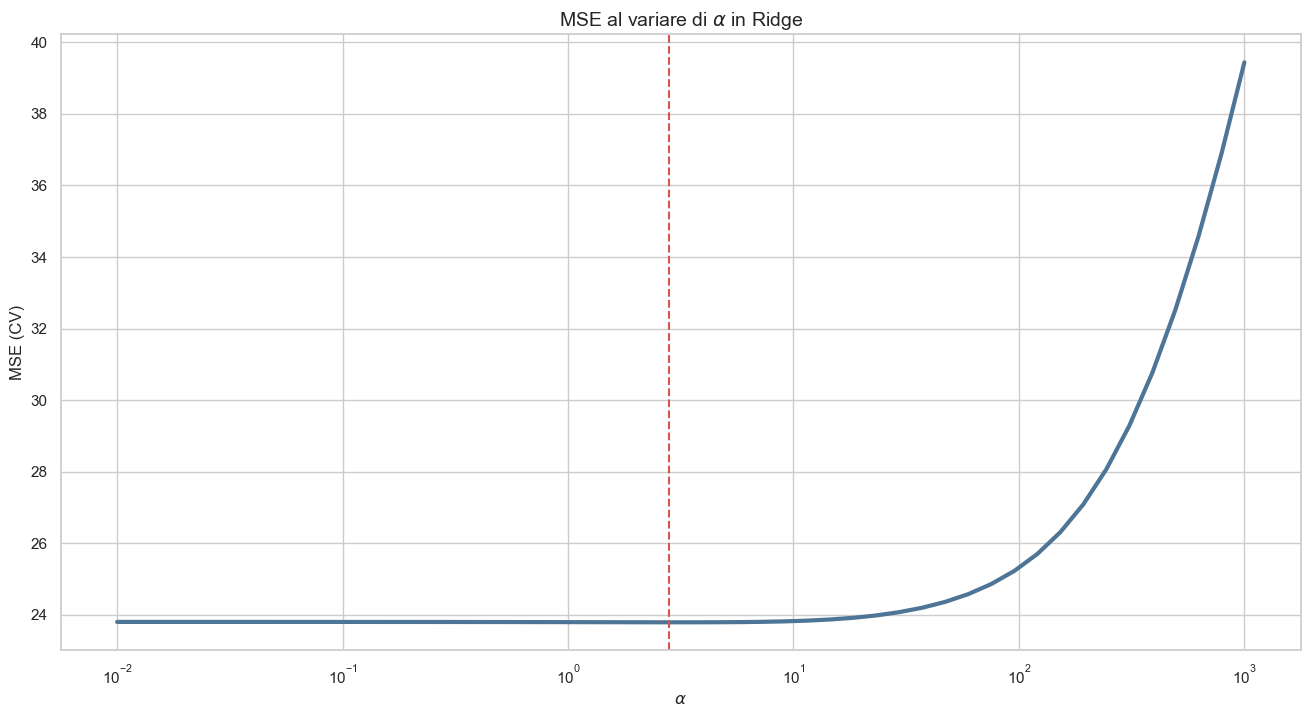

Miglior valore per alpha: 2.81177. MSE=23.794


In [70]:
min_index = np.argmin(scores[:,1])
best_alpha = scores[min_index,0]
fig, ax = plt.subplots(figsize=(16, 8))
sns.lineplot(x=scores[:,0], y=scores[:,1], color=colors[8], linewidth=3, ax=ax)
ax.axvline(best_alpha, color=colors[2], ls='--')
ax.set_xscale('log')
ax.set_xlabel(r'$\alpha$')
ax.set_ylabel('MSE (CV)')
ax.set_title(r'MSE al variare di $\alpha$ in Ridge')
plt.show()
print('Miglior valore per alpha: {0:.5f}. MSE={1:.3f}'.format(best_alpha, scores[min_index,1]))

Utilizzo di GridSearchCV

In [71]:
param_grid = [{'regression__alpha': domain}]
p = Pipeline([('scaler', StandardScaler()),('regression', Ridge())])

clf = GridSearchCV(p, param_grid, cv=kf10, scoring='neg_mean_squared_error')
clf = clf.fit(X, y)
scores = -clf.cv_results_['mean_test_score']
min_index = np.argmin(scores)
print('Miglior valore per alpha: {0:.5f}. MSE={1:.3f}'.format(domain[min_index], scores[min_index]))

Miglior valore per alpha: 2.81177. MSE=23.787


Utilizza RidgeCV, che ricerca il miglior valore di $\alpha$ mediante leave-one-out cross validation calcolata in forma chiusa. Con `store_cv_results=True` (nelle versioni di scikit-learn precedenti alla 1.5, `store_cv_values=True`) vengono conservati gli errori di leave-one-out per ogni elemento e ogni valore di $\alpha$.

In [72]:
try:
    ridge_cv = RidgeCV(alphas=domain, store_cv_results=True)
except TypeError:
    # versioni di scikit-learn precedenti alla 1.5
    ridge_cv = RidgeCV(alphas=domain, store_cv_values=True)
p = Pipeline([('scaler', StandardScaler()),('regression', ridge_cv)])
r = p.fit(X, y)
reg = r.named_steps['regression']
cv_res = reg.cv_results_ if hasattr(reg, 'cv_results_') else reg.cv_values_
scores = np.mean(cv_res, axis=0)

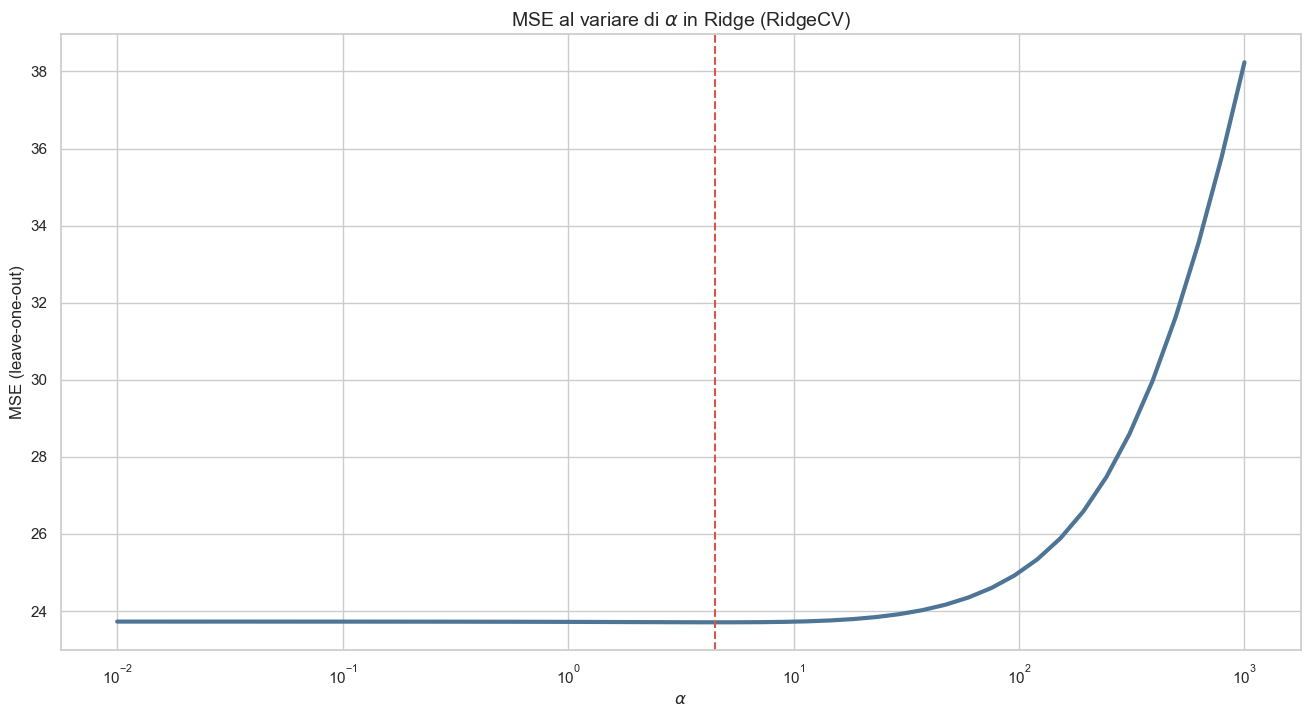

Miglior valore di alpha: 4.498433, MSE: 23.707


In [73]:
best_alpha = reg.alpha_
fig, ax = plt.subplots(figsize=(16, 8))
sns.lineplot(x=domain, y=scores, color=colors[8], linewidth=3, ax=ax)
ax.axvline(best_alpha, color=colors[2], ls='--')
ax.set_xscale('log')
ax.set_xlabel(r'$\alpha$')
ax.set_ylabel('MSE (leave-one-out)')
ax.set_title(r'MSE al variare di $\alpha$ in Ridge (RidgeCV)')
plt.show()
i, = np.where(domain == best_alpha)
print(r'Miglior valore di alpha: {0:.6f}, MSE: {1:.3f}'.format(best_alpha, scores[i][0]))

Valuta Ridge con il valore trovato per $\alpha$, e ne esamina i coefficienti: rispetto alla regressione senza regolarizzazione sono ridotti in modo uniforme, senza che nessuno si annulli.

In [74]:
p = Pipeline([('scaler', StandardScaler()),('regression', Ridge(alpha=best_alpha))])
r = p.fit(X, y)
scores = cross_val_score(estimator=p, X=X, y=y, cv=KFold(n_splits=10, shuffle=True, random_state=SEED+1), scoring='neg_mean_squared_error')
print('alpha: {0:.3f}, MSE: {1:.3f}'.format(best_alpha, -scores.mean()))
pd.Series(r.named_steps['regression'].coef_, index=df.columns[:-1]).round(3)

alpha: 4.498, MSE: 23.741


CRIM      -0.894
ZN         1.018
INDUS      0.046
CHAS       0.695
NOX       -1.938
RM         2.709
AGE       -0.007
DIS       -2.988
RAD        2.373
TAX       -1.809
PTRATIO   -2.025
B          0.847
LSTAT     -3.687
dtype: float64

### Elastic net

Ricerca su una griglia bidimensionale di valori per $\alpha$ e $\gamma$. Escludiamo $\gamma=0$, per il quale l'algoritmo di ottimizzazione usato da scikit-learn per Elastic Net non è adatto (per una penalità solo L2 conviene usare `Ridge`).

In [75]:
alphas_en = np.logspace(-3, 0, 10)
gammas_en = np.linspace(0.1, 1, 10)
scores = []
for a in alphas_en:
    for l in gammas_en:
        p = Pipeline([('scaler', StandardScaler()),('regression', ElasticNet(alpha=a, l1_ratio=l, max_iter=100000))])
        score = cross_val_score(estimator=p, X=X, y=y, cv=kf5, scoring='neg_mean_squared_error')
        scores.append([a, l, -score.mean()])
scores = pd.DataFrame(scores, columns=['alpha', 'gamma', 'MSE'])
best = scores.loc[scores['MSE'].idxmin()]
best_alpha, best_gamma = best['alpha'], best['gamma']
print(r"Migliore coppia: alpha={0:.4f}, gamma={1:.2f}. MSE={2:.3f}".format(best_alpha, best_gamma, best['MSE']))

Migliore coppia: alpha=0.0046, gamma=0.10. MSE=23.820


La heatmap dell'errore sulla griglia mostra che il parametro determinante è $\alpha$: per $\alpha$ piccolo l'errore è praticamente indipendente da $\gamma$, e cresce con $\alpha$ per ogni valore di $\gamma$, perché la regolarizzazione diventa troppo forte. Come per Lasso e Ridge, su questo dataset la soluzione migliore è una regolarizzazione debole, e la scelta del tipo di penalità ha un effetto trascurabile sull'errore.

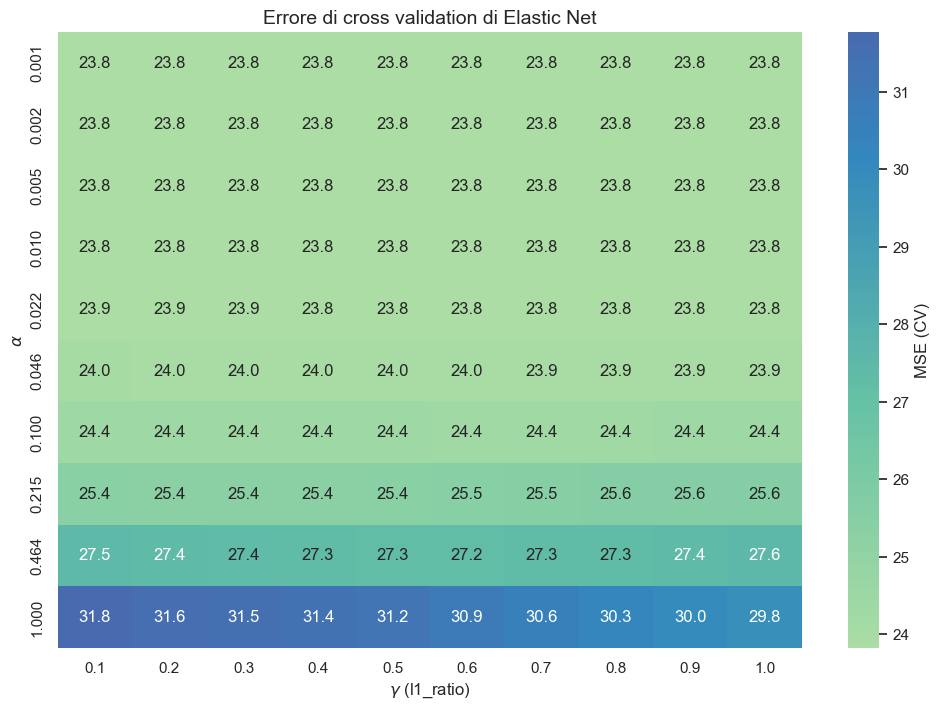

In [76]:
pivot = scores.pivot(index='alpha', columns='gamma', values='MSE')
pivot.index = ['{0:.3f}'.format(a) for a in pivot.index]
pivot.columns = ['{0:.1f}'.format(g) for g in pivot.columns]
plt.figure(figsize=(12, 8))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap=cmap, cbar_kws={'label': 'MSE (CV)'})
plt.xlabel(r'$\gamma$ (l1_ratio)')
plt.ylabel(r'$\alpha$')
plt.title('Errore di cross validation di Elastic Net')
plt.show()

In [77]:
p = Pipeline([('scaler', StandardScaler()),('regression', ElasticNet(alpha=best_alpha, l1_ratio=best_gamma, max_iter=100000))])
r = p.fit(X, y)
scores_cv = cross_val_score(estimator=p, X=X, y=y, cv=KFold(n_splits=10, shuffle=True, random_state=SEED+1), scoring='neg_mean_squared_error')
print('alpha: {0:.4f}, gamma: {1:.2f}; MSE: {2:.3f}'.format(best_alpha, best_gamma, -scores_cv.mean()))

alpha: 0.0046, gamma: 0.10; MSE: 23.745


Utilizzo di GridSearchCV, con la stessa griglia: il risultato coincide con quello della ricerca diretta, perché i fold sono gli stessi.

In [78]:
param_grid = [{'regression__alpha': alphas_en, 'regression__l1_ratio': gammas_en}]
p = Pipeline([('scaler', StandardScaler()),('regression', ElasticNet(max_iter=100000))])

clf = GridSearchCV(p, param_grid, cv=kf5, scoring='neg_mean_squared_error')
clf = clf.fit(X, y)
best_alpha = clf.best_params_['regression__alpha']
best_gamma = clf.best_params_['regression__l1_ratio']
print(r"Migliore coppia: alpha={0:.4f}, gamma={1:.2f}. MSE={2:.3f}".format(best_alpha, best_gamma, -clf.best_score_))

Migliore coppia: alpha=0.0046, gamma=0.10. MSE=23.820


In [79]:
p = Pipeline([('scaler', StandardScaler()),('regression', ElasticNet(alpha=best_alpha, l1_ratio=best_gamma, max_iter=100000))])
r = p.fit(X, y)
scores_cv = cross_val_score(estimator=p, X=X, y=y, cv=KFold(n_splits=10, shuffle=True, random_state=SEED+1), scoring='neg_mean_squared_error')
print('alpha: {0:.4f}, gamma: {1:.2f}; MSE: {2:.3f}'.format(best_alpha, best_gamma, -scores_cv.mean()))
results.append(['Regression Elastic Net, all features, scaled, alpha={0:.4f}, gamma={1:.2f}, CV'.format(best_alpha, best_gamma),
                mean_squared_error(y, r.predict(X)), -scores_cv.mean()])

alpha: 0.0046, gamma: 0.10; MSE: 23.745


## Confronto finale

Riassumiamo gli errori raccolti in `results`: per ogni modello, l'errore sul training set e la stima dell'errore su dati nuovi (test set o cross validation). Alcune osservazioni:

- la differenza tra le due colonne è l'**ottimismo** dell'errore di training, piccolo per i modelli semplici e più grande per quelli flessibili;
- su una sola feature, il passo decisivo è l'uso di funzioni base polinomiali, che riducono il bias; la regolarizzazione da sola non aiuta;
- usare tutte le feature riduce ancora l'errore in modo sostanziale, mentre la regolarizzazione, con $\alpha$ scelto per cross validation, porta miglioramenti piccoli rispetto alla variabilità della stima: con $506$ elementi e $13$ feature la regressione lineare non è in grave overfitting.

In [80]:
summary = pd.DataFrame(results, columns=['modello', 'MSE training', 'MSE test / CV'])
summary.round(3)

,modello,MSE training,MSE test / CV
0,"Regression, 1 feature",36.524,46.336
1,"Regression, 1 feature, scaled",36.524,46.336
2,"Regression, 1 feature, scaled, CV",38.483,38.714
3,"Regression L1, 1 feature, scaled, CV, alpha=0.5",38.733,39.261
4,"Regression L2, 1 feature, scaled, CV, alpha=0.5",38.483,39.042
5,"Regression Elastic Net, 1 feature, scaled, CV,...",41.973,42.380
6,"Regression, Polynomial, 1 feature, scaled, deg...",28.884,29.396
7,"Regression L1, Polynomial, 1 feature, scaled, ...",28.924,29.440
8,"Regression Linear, all features, scaled, CV",21.895,23.828
9,"Regression Lasso, alpha=0.5, all features, sca...",26.056,27.756


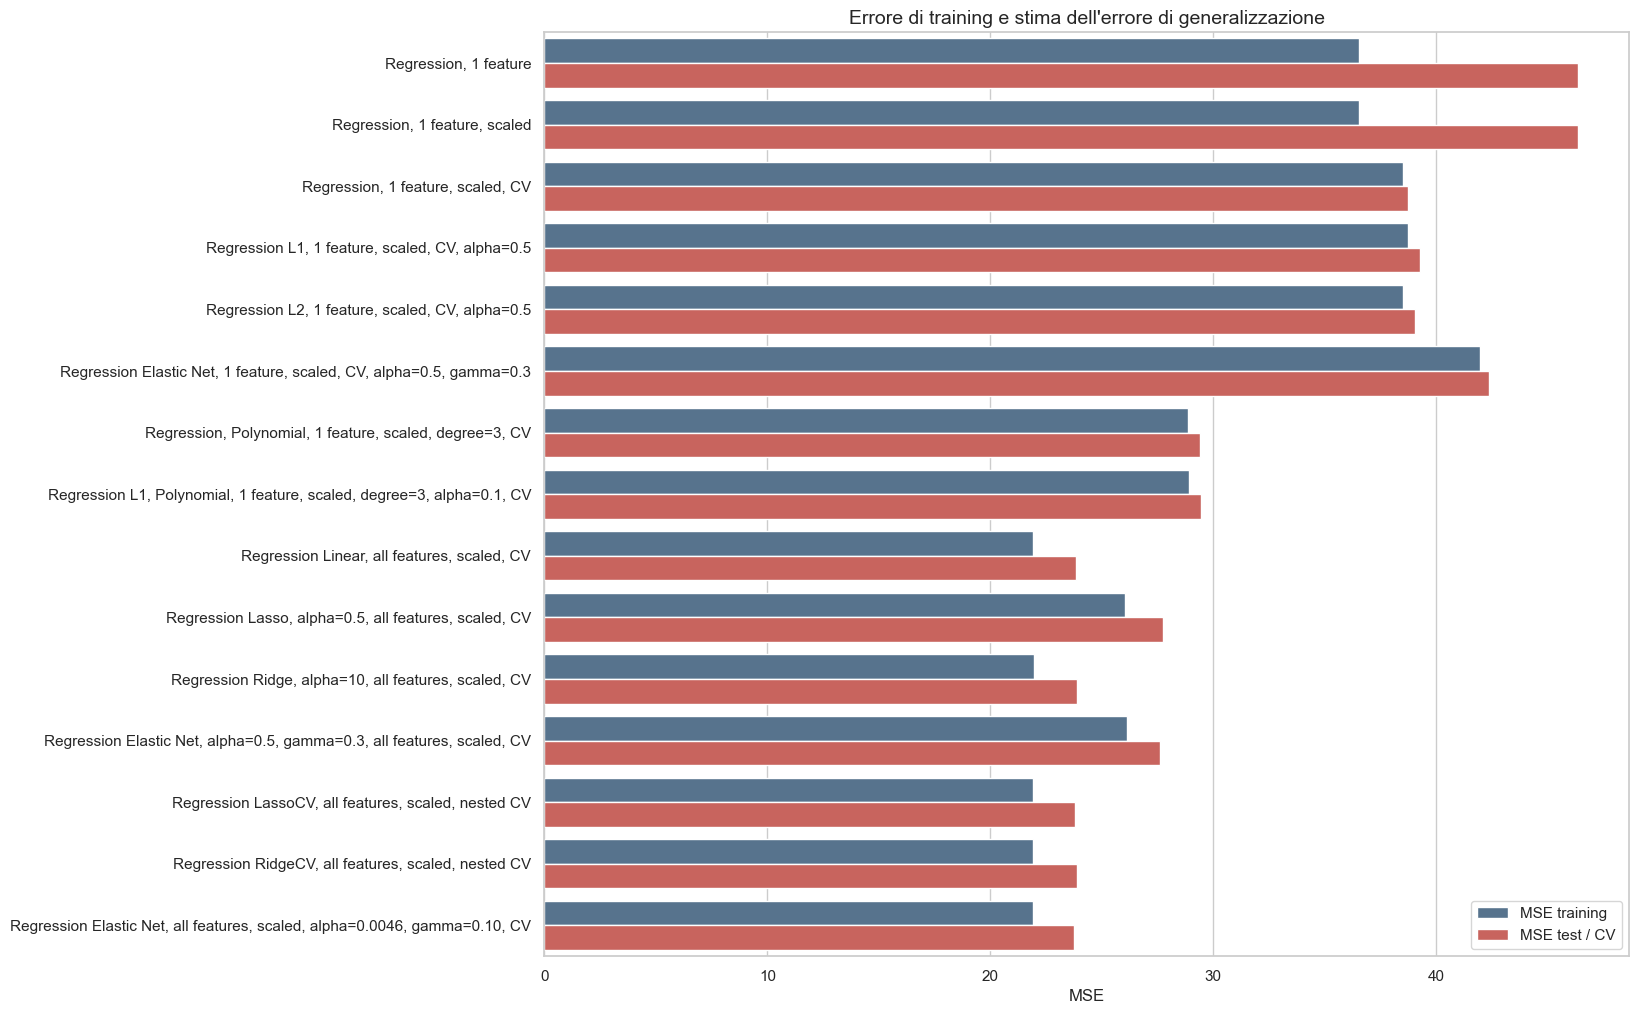

In [81]:
long = summary.melt(id_vars='modello', var_name='errore', value_name='MSE')
plt.figure(figsize=(14, 12))
sns.barplot(data=long, x='MSE', y='modello', hue='errore', palette=[colors[8], colors[2]], orient='h')
plt.ylabel('')
plt.title('Errore di training e stima dell\'errore di generalizzazione')
plt.legend(loc='lower right')
plt.show()